## Credit Card Fraud Detection

In this project you will predict fraudulent credit card transactions with the help of Machine learning models. Please import the following libraries to get started.

### Business understanding
Credit card fraud is any dishonest act or behaviour to obtain information without proper authorisation from the account holder for financial gain. Among different ways of committing frauds, skimming is the most common one, which is a way of duplicating information that is located on the magnetic strip of the card. Apart from this, following are the other ways:

1. Manipulation/alteration of genuine cards
2. Creation of counterfeit cards
3. Stealing/loss of credit cards
4. Fraudulent telemarketing

### Understanding the data:

The data set includes credit card transactions made by European cardholders over a period of two days in September 2013. Out of a total of 2,84,807 transactions, 492 were fraudulent. This data set is highly unbalanced, with the positive class (frauds) accounting for 0.172% of the total transactions. The data set has also been modified with principal component analysis (PCA) to maintain confidentiality. Apart from ‘time’ and ‘amount’, all the other features (V1, V2, V3, up to V28) are the principal components obtained using PCA. The feature 'time' contains the seconds elapsed between the first transaction in the data set and the subsequent transactions. The feature 'amount' is the transaction amount. The feature 'class' represents class labelling, and it takes the value of 1 in cases of fraud and 0 in others.

In [4]:
# pip install xgboost

In [1]:
import os
import time

#importng necessary libraries
import numpy as np
import pandas as pd

##libraries for Visualization
import matplotlib.pyplot as plt
from matplotlib import gridspec
%matplotlib inline
import seaborn as sns

# libraries for modeling
from sklearn import linear_model
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, PowerTransformer

#model evaluation
from sklearn import metrics
from sklearn.metrics import make_scorer, f1_score, classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc

# oversampling techniques
from imblearn import over_sampling
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

import warnings
warnings.filterwarnings('ignore')

## Exploratory data analysis

In [2]:
plt.style.available

['Solarize_Light2',
 '_classic_test_patch',
 '_mpl-gallery',
 '_mpl-gallery-nogrid',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

In [3]:
plt.style.use('seaborn-v0_8-dark')

In [4]:
# from google.colab import drive
# drive.mount('/Users/binayyadab/Desktop/Python_code_Files_udemy/Fraud_detection')

In [5]:
# # extract file from zip file stored in google drive
# import zipfile
# zip_ref = zipfile.ZipFile("/content/drive/MyDrive/upgrad/Fraud_Detection/creditcard.csv.zip", 'r')
# zip_ref.extractall("/content/drive/MyDrive/upgrad/Fraud_Detection//tmp")
# zip_ref.close()

In [6]:
#defining the path and loading data
path = "/Users/binayyadab/Desktop/Python_code_Files_udemy/Fraud_detection/"
df = pd.read_csv(path+'creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
#observe the different feature type present in the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [8]:
#convering the time colum to hours
df['Time_min'] = df['Time'].apply(lambda x: int(x/60))
df['Time_hr'] = df['Time'].apply(lambda x: int((x/3600)))

In [9]:
df[['Time','Amount','Class']].describe()

,Time,Amount,Class
count,284807.000000,284807.000000,284807.000000
mean,94813.859575,88.349619,0.001727
std,47488.145955,250.120109,0.041527
min,0.000000,0.000000,0.000000
25%,54201.500000,5.600000,0.000000
50%,84692.000000,22.000000,0.000000
75%,139320.500000,77.165000,0.000000
max,172792.000000,25691.160000,1.000000


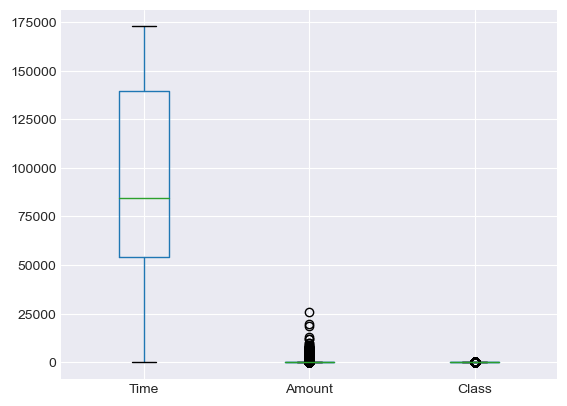

In [10]:
df[['Time','Amount','Class']].boxplot()
plt.show()

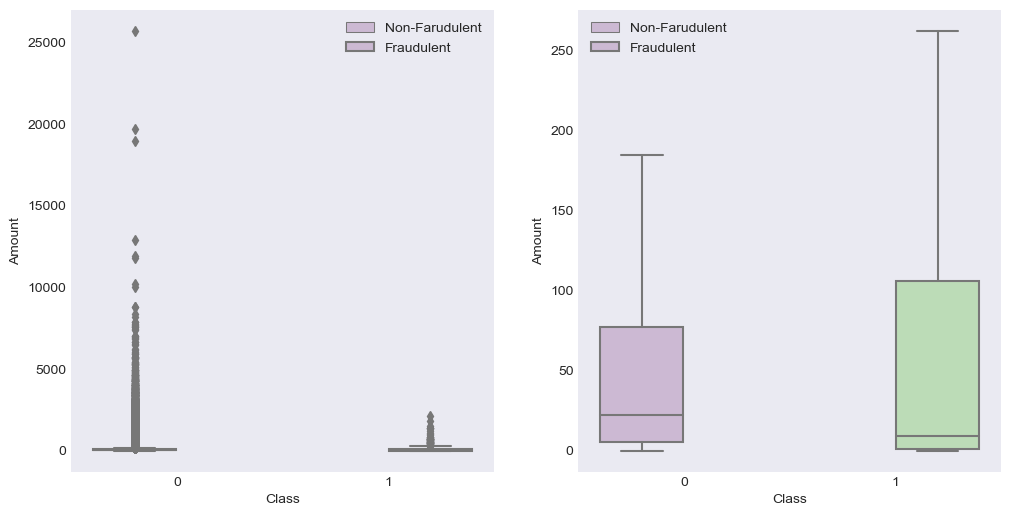

In [11]:
# prompt: plot boxplot for amount with distribution of  non-fraud and fraud

#Creating a box plot for the amount feature with distribution of  non-fraud and fraud
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,6))
s1 = sns.boxplot(ax = ax1, x="Class", y="Amount", hue="Class",data=df, palette="PRGn",showfliers=True)
s1.legend(labels=['Non-Farudulent', 'Fraudulent'])
s2 = sns.boxplot(ax = ax2, x="Class", y="Amount", hue="Class",data=df, palette="PRGn",showfliers=False)
s2.legend(labels=['Non-Farudulent', 'Fraudulent'])
plt.show()

In [12]:
#classwise amount distribution
df['Amount'].groupby(df['Class']).describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [13]:
amount_stats = df['Amount'].groupby(df['Class']).describe()
amount_stats.index = amount_stats.index.map({0: 'Non-Fraud', 1: 'Fraud'})
amount_stats

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Non-Fraud,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
Fraud,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


#### Observations:-
- Interesting to note "all transaction amounts > 10K in Genuine Class only
- There are no outliers in fraudulent Transactions
- fraud amounts are less than 3000

In [14]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V23,V24,V25,V26,V27,V28,Amount,Class,Time_min,Time_hr
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,0,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,0,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,0,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0,0,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0,0,0


In [15]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V23,V24,V25,V26,V27,V28,Amount,Class,Time_min,Time_hr
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0,2879,47
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0,2879,47
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0,2879,47
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0,2879,47
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0,2879,47


Here we will observe the distribution of our classes

In [16]:
classes = df['Class'].value_counts()
normal_share = classes[0]/df['Class'].count()*100
fraud_share = classes[1]/df['Class'].count()*100
print('Percentage of normal transactions = ',normal_share)
print('Percentage of fraud transactions = ',fraud_share)

Percentage of normal transactions =  99.82725143693798
Percentage of fraud transactions =  0.1727485630620034


In [17]:
class_names = {0:'Not Fraud', 1:'Fraud'}
print(df.Class.value_counts().rename(index = class_names))

Class
Not Fraud    284315
Fraud           492
Name: count, dtype: int64


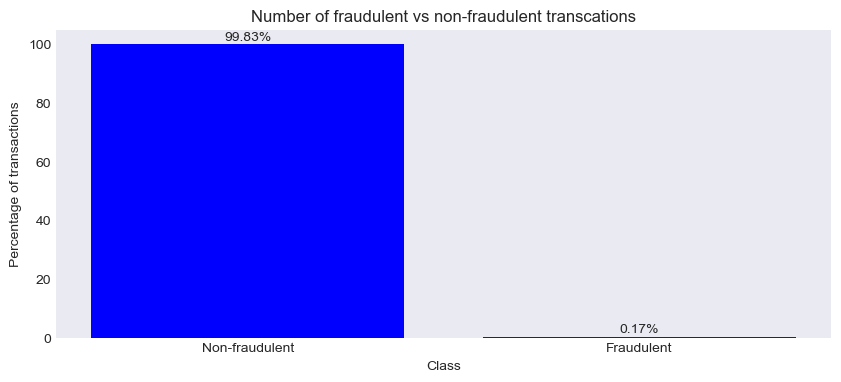

In [18]:
# Create a bar plot for the number and percentage of fraudulent vs non-fraudulent transcations
plt.figure(figsize=(10,4))
shares = [normal_share, fraud_share]
labels = ['Non-fraudulent', 'Fraudulent']
plt.bar(labels, shares, color=['blue', 'darkred'])
plt.title('Number of fraudulent vs non-fraudulent transcations')
plt.xlabel('Class')
plt.ylabel('Percentage of transactions')
# Display the percentage values on top of the bars
for i, share in enumerate(shares):
    plt.text(i, share + 0.5, f'{share:.2f}%', ha='center', va='bottom')
plt.show()

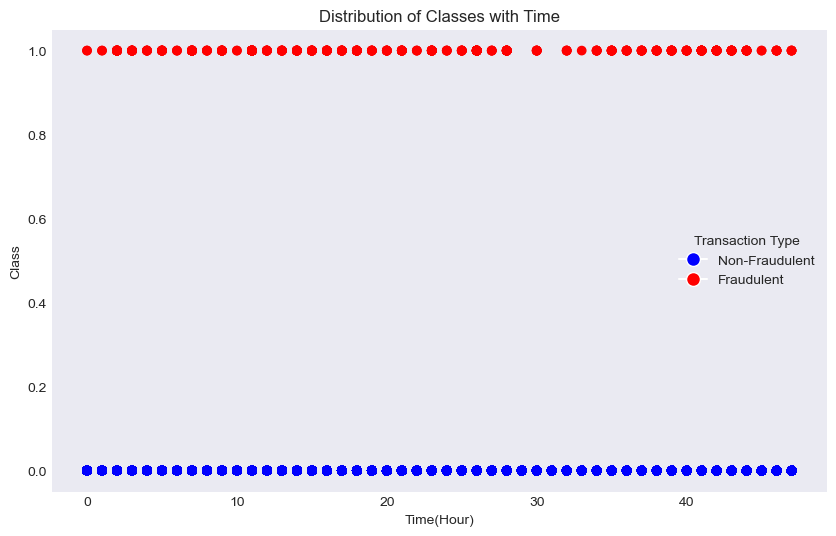

In [19]:
# Create a scatter plot to observe the distribution of classes with time
plt.figure(figsize=(10, 6))
# Use a color map to assign colors based on the 'Class' column
colors = df['Class'].map({0: 'blue', 1: 'red'})

plt.scatter(x='Time_hr', y='Class', data=df,c=colors)
plt.title('Distribution of Classes with Time')
plt.xlabel('Time(Hour)')
plt.ylabel('Class')

# Create a custom legend with correct labels

plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=10, label='Non-Fraudulent'),
                    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=10, label='Fraudulent')],
           title='Transaction Type')
plt.show()

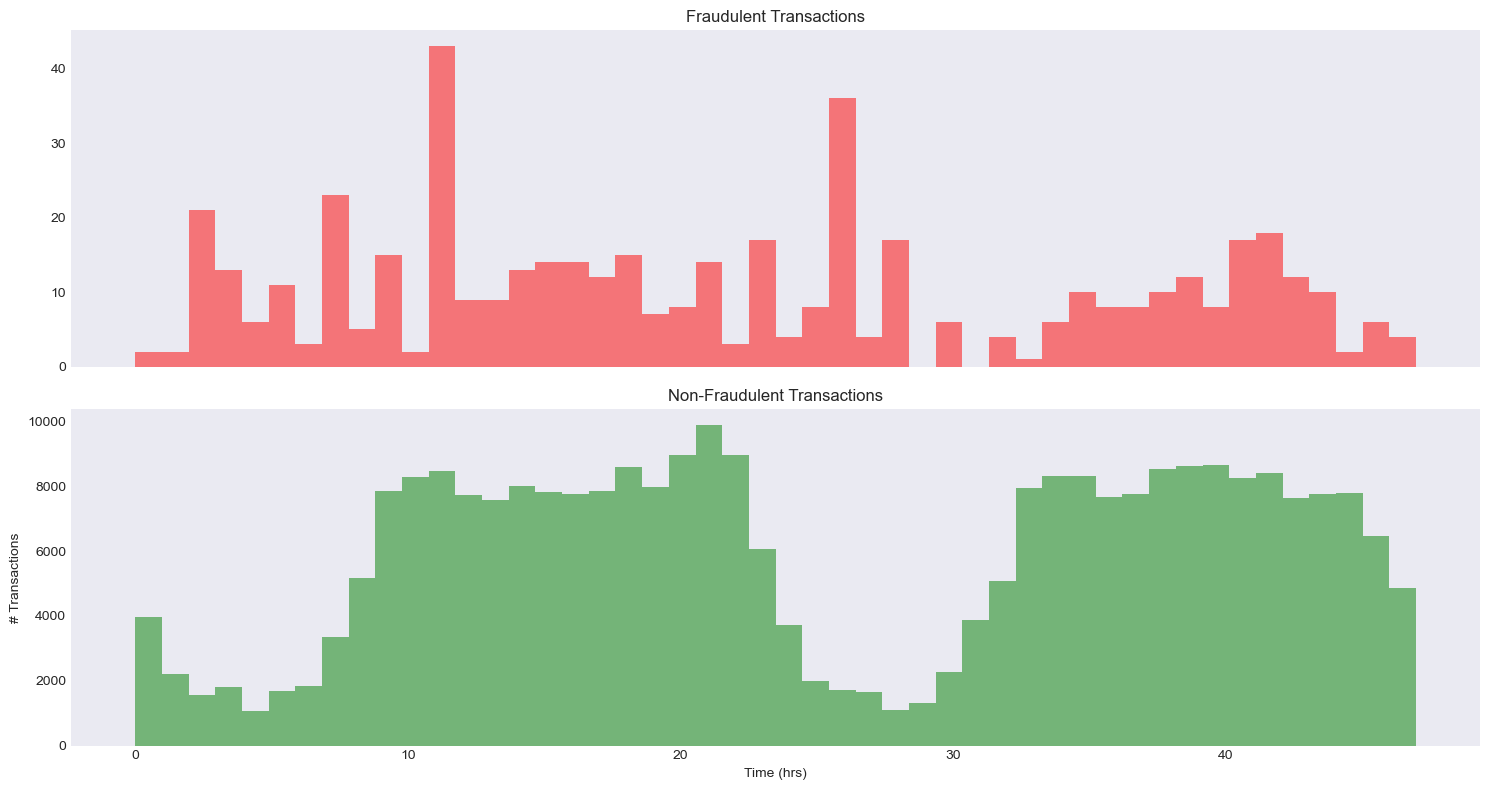

In [20]:
# Create a histogram to observe the distribution of classes with time
fig, (ax1,ax2) = plt.subplots(2,1, sharex=True, figsize=(15,8))

ax1.hist(df.Time_hr[df.Class==1],bins=48,color='r',alpha=0.5)
ax1.set_title('Fraudulent Transactions')

ax2.hist(df.Time_hr[df.Class==0],bins=48,color='g',alpha=0.5)
ax2.set_title('Non-Fraudulent Transactions')

plt.xlabel('Time (hrs)')
plt.ylabel('# Transactions')
# Adjust the layout to prevent overlap
plt.tight_layout()

# Show the plots
plt.show()

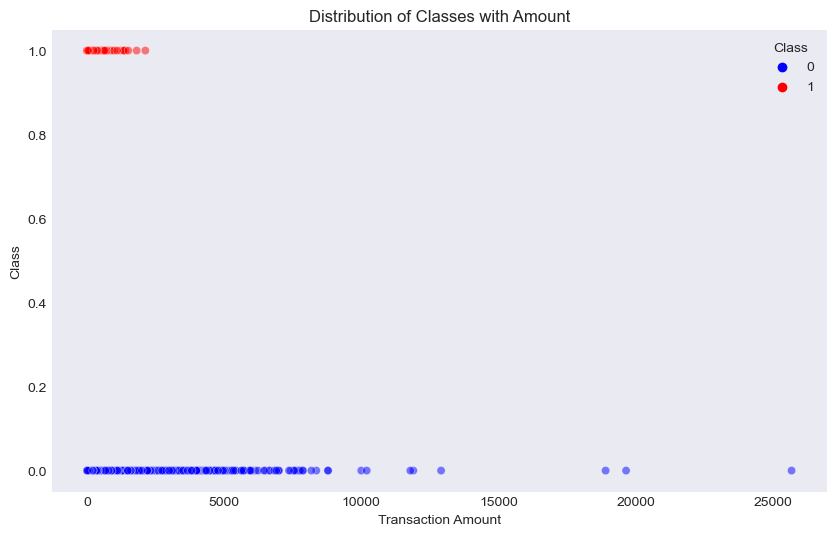

In [21]:
# Create a scatter plot to observe the distribution of classes with Amount
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Amount', y='Class', data=df, hue='Class', palette={0: 'blue', 1: 'red'},alpha=0.5)
plt.title('Distribution of Classes with Amount')
plt.xlabel('Transaction Amount')
plt.ylabel('Class')
plt.show()

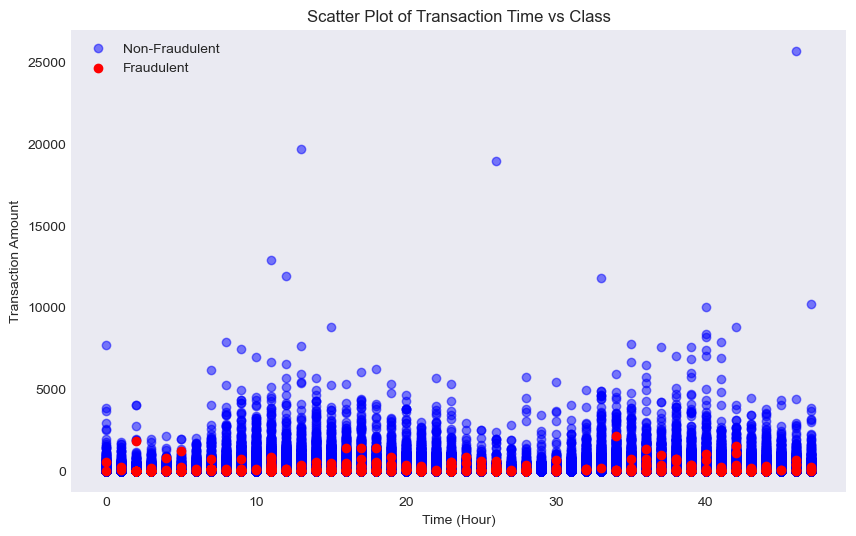

In [22]:
# Create a scatter plot to observe the distribution of classes with time
plt.figure(figsize=(10, 6))
# Plot non-fraudulent transactions
plt.scatter(df[df['Class'] == 0]['Time_hr'], df[df['Class'] == 0]['Amount'],
            color='blue', label='Non-Fraudulent', alpha=0.5)

# Plot fraudulent transactions
plt.scatter(df[df['Class'] == 1]['Time_hr'], df[df['Class'] == 1]['Amount'],
            color='red', label='Fraudulent')

# Add labels and title
plt.xlabel('Time (Hour)')
plt.ylabel('Transaction Amount')
plt.title('Scatter Plot of Transaction Time vs Class')
plt.legend()
plt.show()

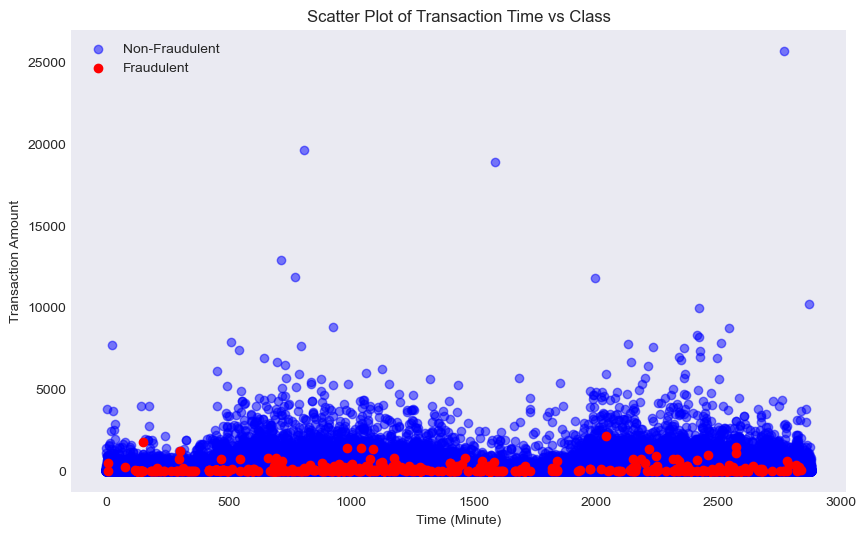

In [23]:
# Create a scatter plot to observe the distribution of classes with time
plt.figure(figsize=(10, 6))
# Plot non-fraudulent transactions
plt.scatter(df[df['Class'] == 0]['Time_min'], df[df['Class'] == 0]['Amount'],
            color='blue', label='Non-Fraudulent', alpha=0.5)

# Plot fraudulent transactions
plt.scatter(df[df['Class'] == 1]['Time_min'], df[df['Class'] == 1]['Amount'],
            color='red', label='Fraudulent')

# Add labels and title
plt.xlabel('Time (Minute)')
plt.ylabel('Transaction Amount')
plt.title('Scatter Plot of Transaction Time vs Class')
plt.legend()
plt.show()

#### Observation:
- The fraudtransactions taken place uniformly the is no specific pattern.
- From histogram we can observe that most of the fraudulent transactions occured during the day time

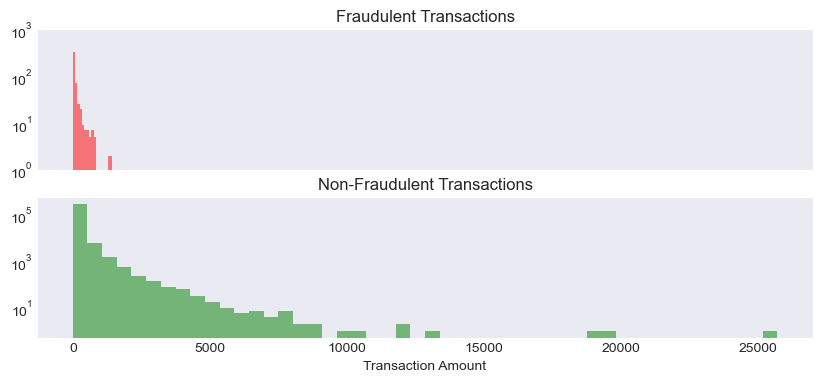

In [24]:
fig, (ax3,ax4) = plt.subplots(2,1,sharex = True, figsize=(10,4))
ax3.hist(df.Amount[df.Class==1],bins=25,color='r',alpha=0.5)
ax3.set_yscale('log')
ax3.set_ylim(1,1000)
ax3.set_title('Fraudulent Transactions')


ax4.hist(df.Amount[df.Class==0],bins=48,color='g',alpha=0.5)
ax4.set_yscale('log')
ax4.set_title('Non-Fraudulent Transactions')
plt.xlabel('Transaction Amount')
plt.show()

#### Observations:-
- The amount column is skwed
- Also this amount feature is not on same scale as principle components.
- I will standardize the values of the 'Amount' feature using StandardScalar and save in for later use.



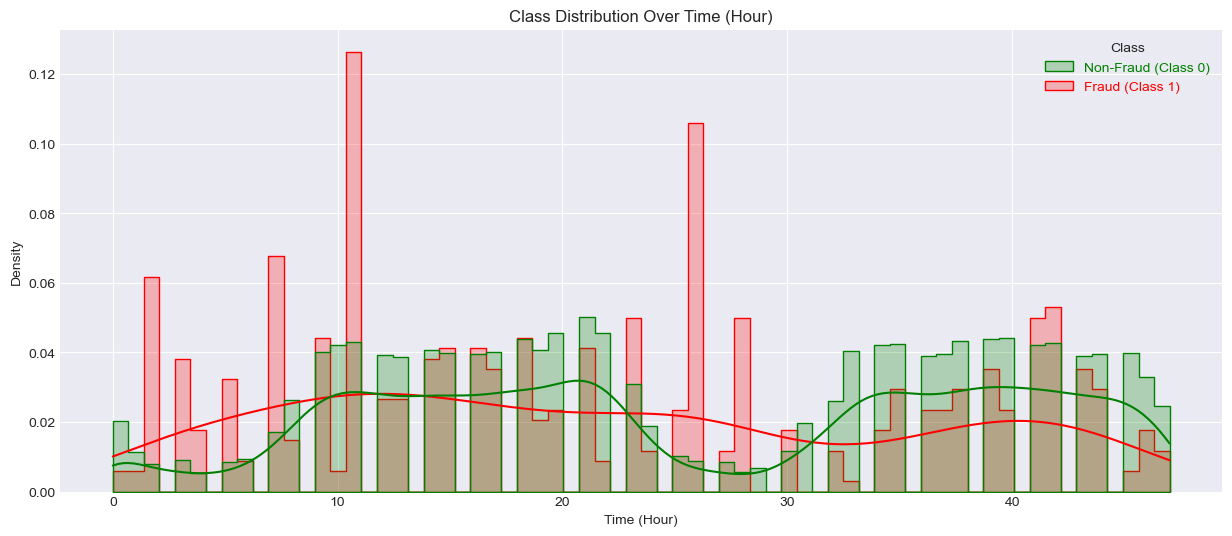

In [25]:
plt.figure(figsize=(15, 6))

# Plot the distribution of the 'Time_hour' variable for both classes with respect to class color
sns.histplot(data=df, x='Time_hr', hue='Class', element='step', stat='density', common_norm=False, kde=True, palette={0: 'green', 1: 'red'})

# Customize the legend with class-specific colors and labels
legend_labels = ['Non-Fraud (Class 0)', 'Fraud (Class 1)']
legend_colors = ['green', 'red']

for i, text in enumerate(plt.gca().get_legend().get_texts()):
    text.set_text(legend_labels[i])
    text.set_color(legend_colors[i])

plt.title('Class Distribution Over Time (Hour)')
plt.xlabel('Time (Hour)')
plt.ylabel('Density')
# plt.xlim([499,561])
plt.grid(True)

plt.show()

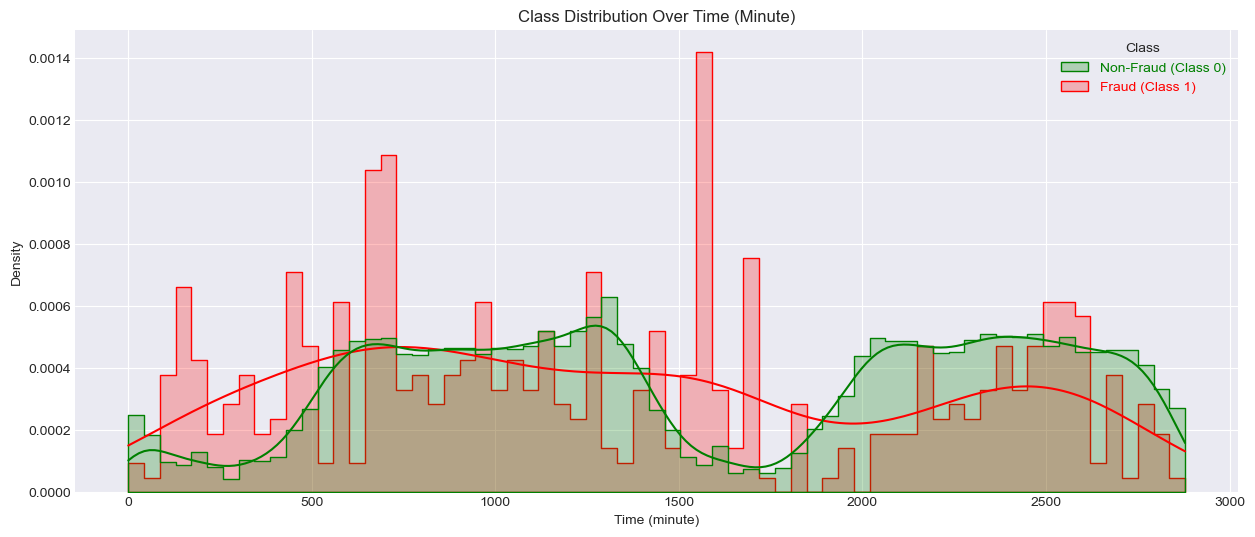

In [26]:
plt.figure(figsize=(15, 6))

# Plot the distribution of the 'Time_hour' variable for both classes with respect to class color
sns.histplot(data=df, x='Time_min', hue='Class', element='step', stat='density', common_norm=False, kde=True, palette={0: 'green', 1: 'red'})

# Customize the legend with class-specific colors and labels
legend_labels = ['Non-Fraud (Class 0)', 'Fraud (Class 1)']
legend_colors = ['green', 'red']

for i, text in enumerate(plt.gca().get_legend().get_texts()):
    text.set_text(legend_labels[i])
    text.set_color(legend_colors[i])

plt.title('Class Distribution Over Time (Minute)')
plt.xlabel('Time (minute)')
plt.ylabel('Density')
# plt.xlim([499,561])
plt.grid(True)

plt.show()

In [27]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class', 'Time_min', 'Time_hr'],
      dtype='object')

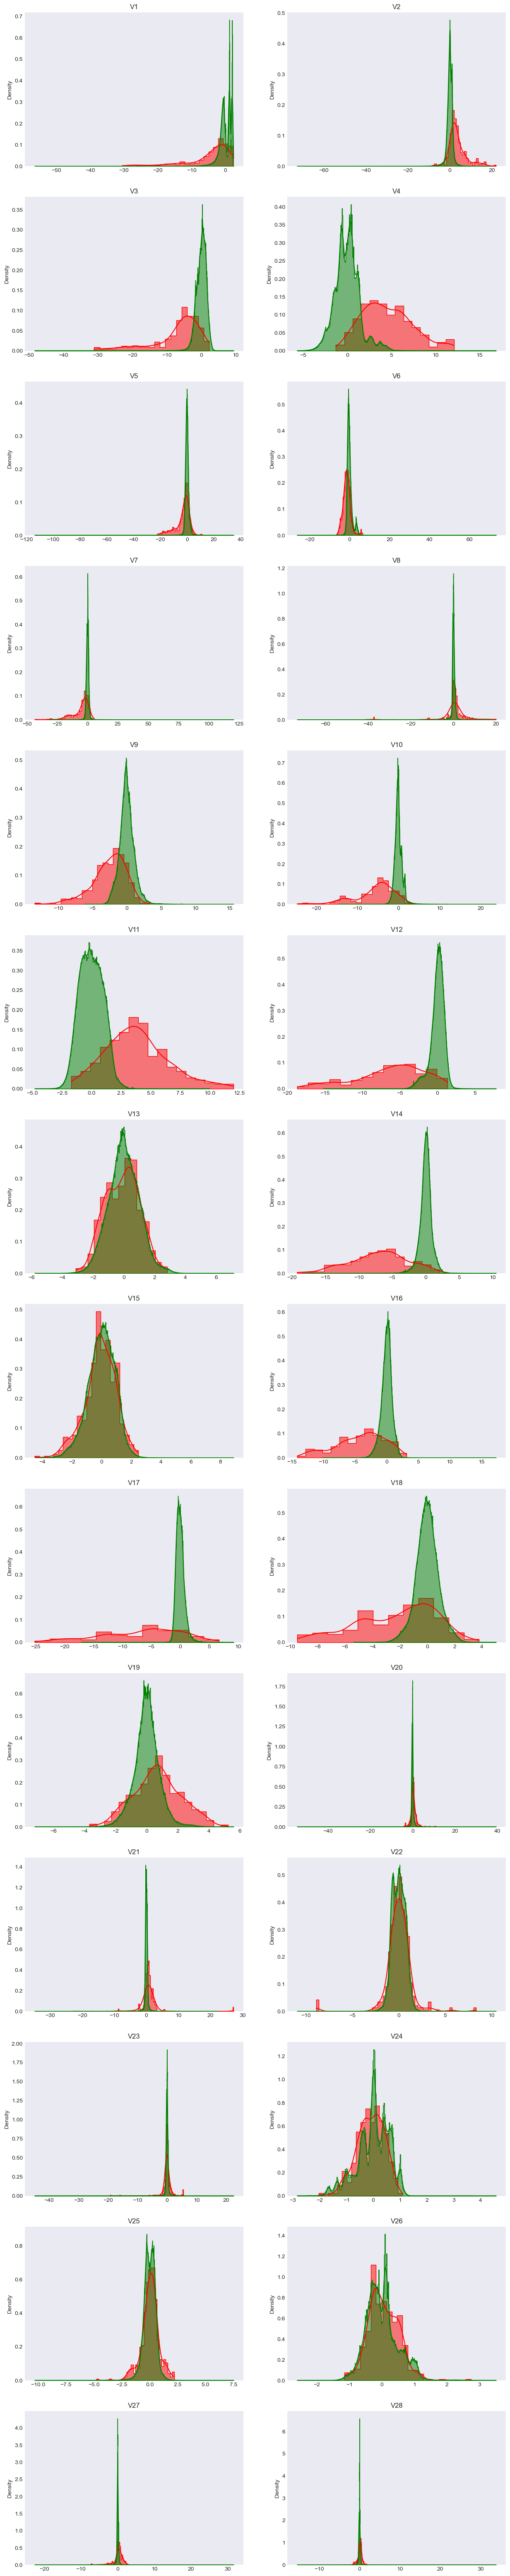

In [28]:
columns = df.iloc[:,1:29].columns
frauds = df.Class == 1
genuine = df.Class == 0

grid = gridspec.GridSpec(14,2)
plt.figure(figsize=(15,20*4))

for n, col in enumerate(df[columns]):
    ax = plt.subplot(grid[n])
    sns.histplot(df[col][frauds],color='r',element='step', stat='density', common_norm=False, kde=True)
    sns.histplot(df[col][genuine],color='g',element='step', stat='density', common_norm=False, kde=True)
    ax.set_ylabel('Density')
    ax.set_title(str(col))
    ax.set_xlabel('')
plt.show()

- Removing the features where we see a significant overlap in both classes
    - 'V5','V6','V8','V13','V15','V20','V21','V22','V23','V24','V25','V26','V28'

In [29]:
# Drop unnecessary columns(Time)
#including Time as we have already derives required featyures out of it
drop_cols = ['Time','V5','V6','V8','V13','V15','V20','V21','V22','V23','V24','V25','V26','V28','Time_min']
df_2 = df.drop(drop_cols, axis=1)
df_2.columns

Index(['V1', 'V2', 'V3', 'V4', 'V7', 'V9', 'V10', 'V11', 'V12', 'V14', 'V16',
       'V17', 'V18', 'V19', 'V27', 'Amount', 'Class', 'Time_hr'],
      dtype='object')

### HeatMap

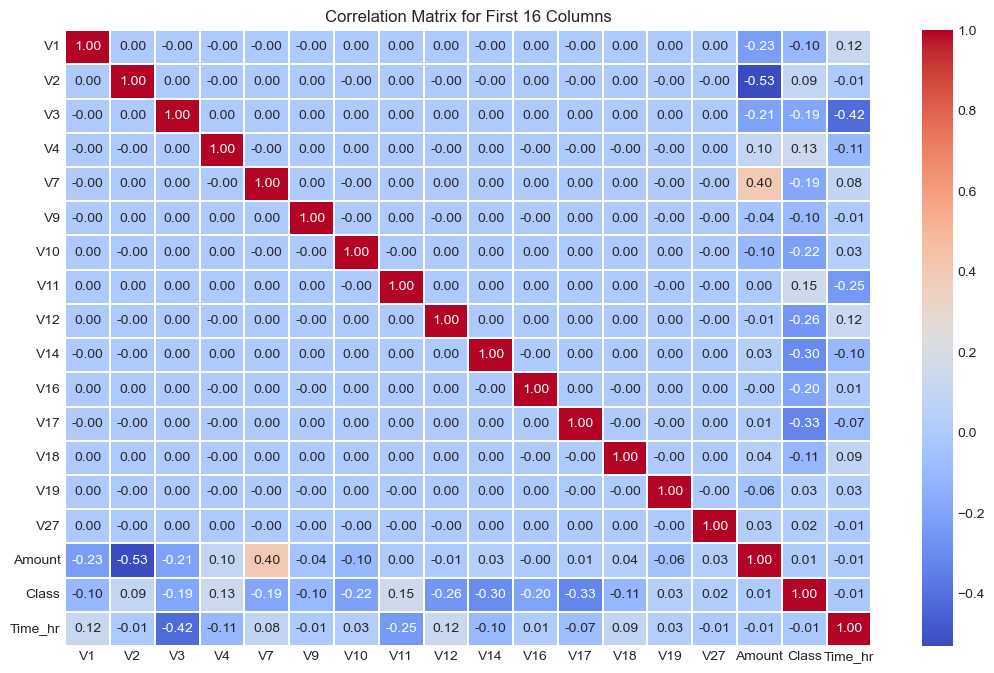

In [30]:
# correlation_matrix = df_2.iloc[:, :17].corr()
correlation_matrix = df_2.corr()

# Plotting the heatmap for visualization
plt.figure(figsize=(13, 8))
sns.heatmap(correlation_matrix, linewidths=0.1, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix for First 16 Columns')
plt.show()

### Splitting the data into train & test data

In [31]:
y = df_2.Class #class variable
x = df_2.drop('Class', axis=1) #features

In [32]:
x.columns

Index(['V1', 'V2', 'V3', 'V4', 'V7', 'V9', 'V10', 'V11', 'V12', 'V14', 'V16',
       'V17', 'V18', 'V19', 'V27', 'Amount', 'Time_hr'],
      dtype='object')

In [33]:
# train test split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42, stratify=y)

##### Preserve X_test & y_test to evaluate on the test data once you build the model

In [34]:
print(np.sum(y))
print(np.sum(y_train))
print(np.sum(y_test))

492
369
123


### Standardizing

In [35]:
X_train.columns

Index(['V1', 'V2', 'V3', 'V4', 'V7', 'V9', 'V10', 'V11', 'V12', 'V14', 'V16',
       'V17', 'V18', 'V19', 'V27', 'Amount', 'Time_hr'],
      dtype='object')

In [36]:
X_train.columns

Index(['V1', 'V2', 'V3', 'V4', 'V7', 'V9', 'V10', 'V11', 'V12', 'V14', 'V16',
       'V17', 'V18', 'V19', 'V27', 'Amount', 'Time_hr'],
      dtype='object')

In [37]:
X_train.head()

,V1,V2,V3,V4,V7,V9,V10,V11,V12,V14,V16,V17,V18,V19,V27,Amount,Time_hr
17884,-0.840333,-0.526032,1.730303,-0.808008,0.056146,0.525878,-0.905381,0.329336,1.038813,-0.514504,0.333716,-0.547176,0.093876,0.238069,0.073129,110.00,8
232246,-3.756704,-0.853465,-0.449739,-2.423920,0.123247,0.962507,-1.103336,-0.023132,0.507055,0.324608,1.423536,-1.248222,0.866346,-0.452917,-0.862160,138.96,40
208554,-2.021166,1.590508,-0.539136,-1.551936,-1.103548,0.720191,-1.451599,-1.609796,0.425411,-1.590375,0.655528,0.579286,0.127909,-0.933770,0.543648,131.03,38
11464,1.377495,-0.437941,0.643866,-0.243826,-0.600576,0.776010,0.103307,0.424536,-2.612572,0.884224,0.529134,1.386995,-1.545854,0.731178,-0.011904,20.00,5
109718,-0.365864,1.084303,1.232877,0.867853,0.747583,-0.492603,-0.008579,-0.565222,-0.265531,0.369115,-0.321379,-0.174675,0.141157,0.402857,0.412181,9.09,19


### Plotting the distribution of a variable

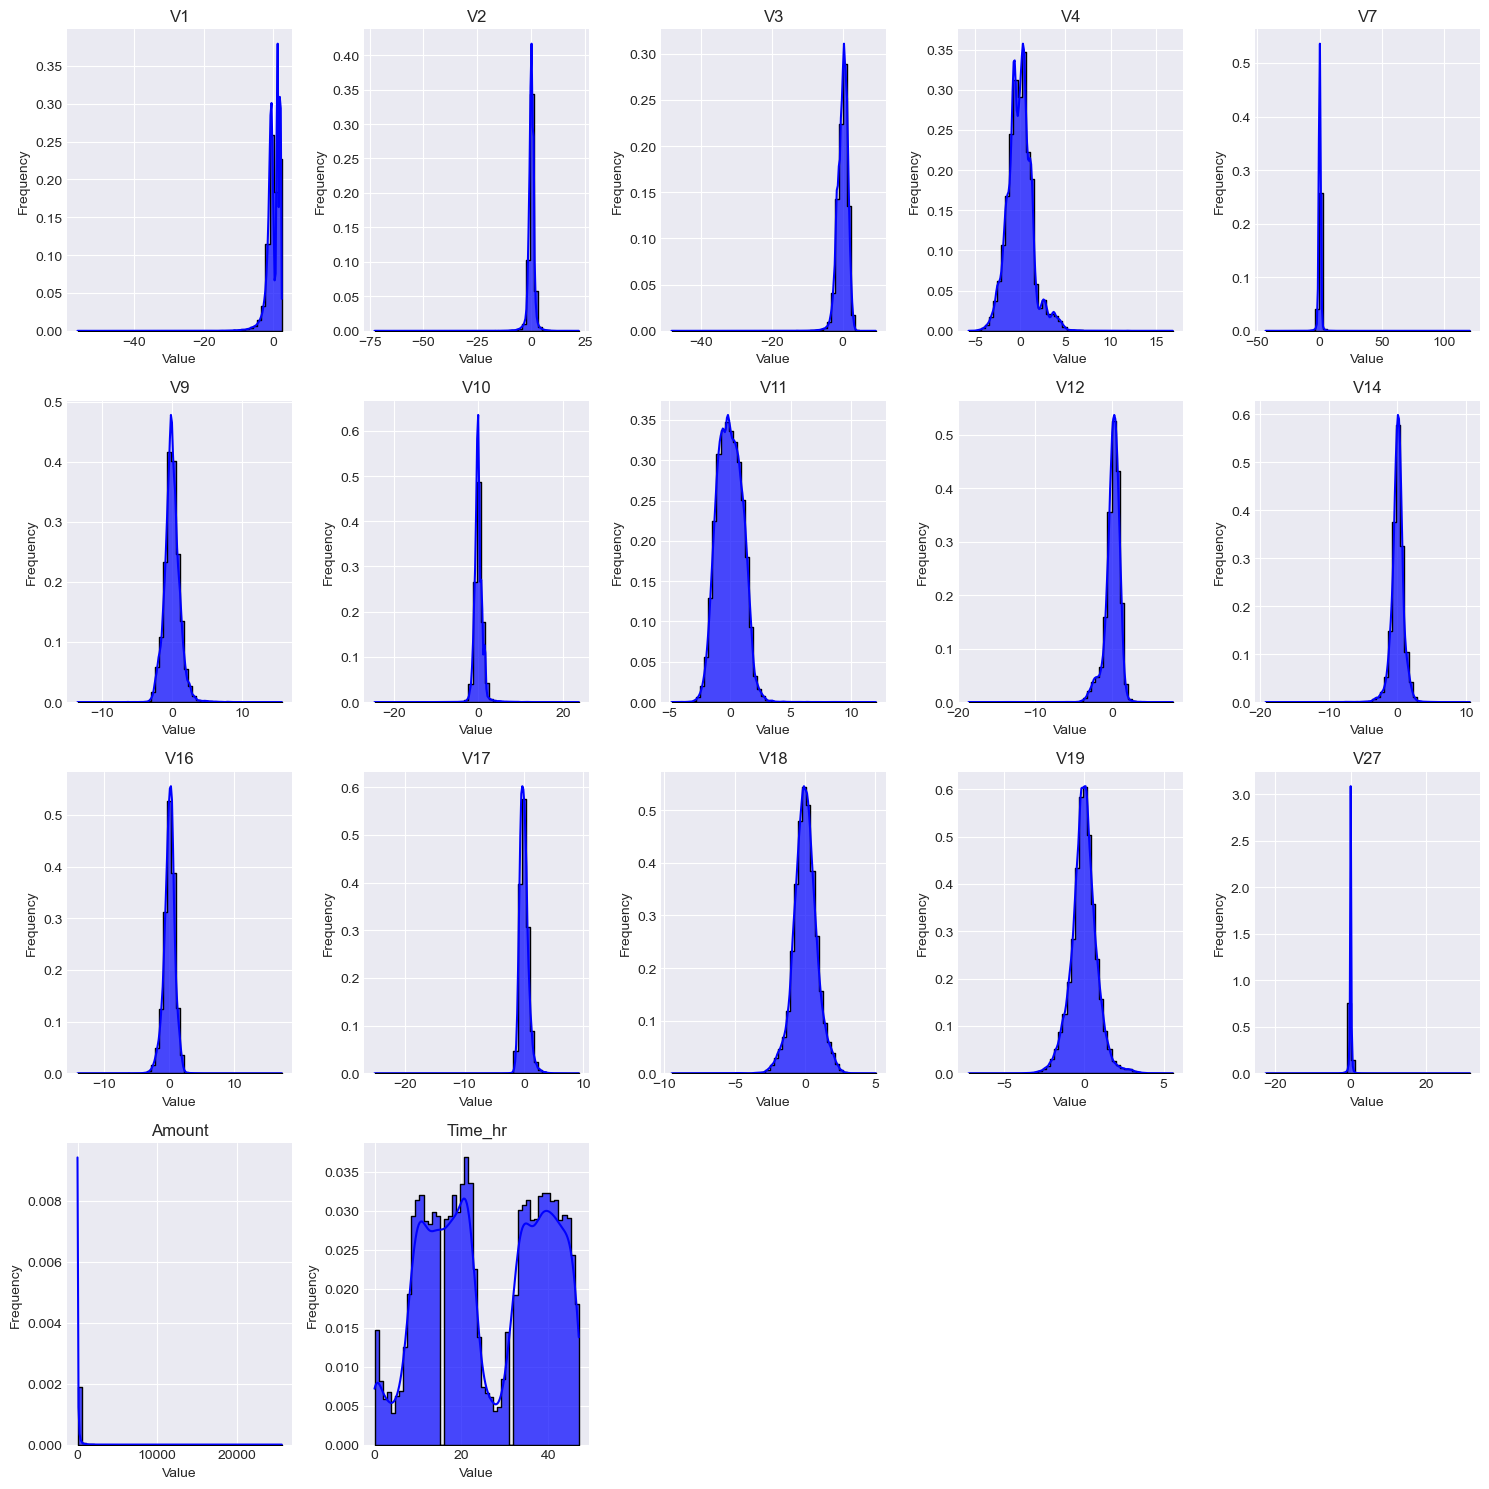

In [38]:
#ploting all the varibales  to see their distribution
var_list = X_train.columns
plt.figure(figsize=(15, 15))

# Number of features
n_features = X_train.shape[1]

# Loop through each feature and plot its histogram
for i in range(n_features):
    plt.subplot((n_features + 4) // 5, 5, i + 1)  # Adjust subplot grid (5 columns)
    sns.histplot(X_train.iloc[:, i], bins=50, color='blue', edgecolor='black', alpha=0.7, element='step', stat='density', common_norm=False, kde=True)
    plt.title(var_list[i])
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    plt.grid(True)

plt.tight_layout()
plt.show()

- The overal fraud pattern is similar over time there is no significant pattern.
- So we will be removing it.

In [39]:
print(X_train['Amount'].skew())
print(X_train['V1'].skew())

18.464338647936962
-3.3149560514133016


- Both feature V1 and scaledAmount has skweness
- But the Amount column as the highest variance lets apply PowerTransformer to it.

Text(0.5, 1.0, 'Transaction Amounts')

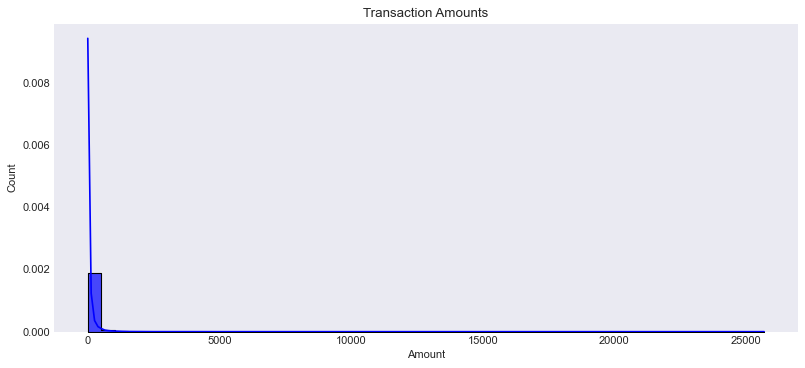

In [40]:
# plotting
plt.figure(figsize=(12,5), dpi=80)
sns.histplot(X_train['Amount'], bins=50, color='blue', edgecolor='black', alpha=0.7, element='step', stat='density', common_norm=False, kde=True)
plt.xlabel('Amount')
plt.ylabel('Count')
plt.title('Transaction Amounts')

That's a strong right skew. Let's use a power transform to bring the transaction amounts closer to a normal distribution We'll use the Box-Cox transform in SciPy, but some of the amounts are zero (min = 0 above), so we need to shift the amounts first to make them positive. We'll shift by a very small amount, just.

### If there is skewness present in the distribution use:
- <b>Power Transformer</b> package present in the <b>preprocessing library provided by sklearn</b> to make distribution more gaussian

In [41]:
# - Apply : preprocessing.PowerTransformer(copy=False) to fit & transform the train & test data

# X_train.loc[:,'Amount'] = X_train['Amount'] + 1e-9 # Shift all amounts by 1e-9
# X_test.loc[:,'Amount'] = X_test['Amount'] + 1e-9 # Shift all amounts by 1e-9

pt = PowerTransformer(standardize=True, method='yeo-johnson', copy=False)

X_train['transfomred_Amount'] = pt.fit_transform(X_train[['Amount']])
X_test['transfomred_Amount'] = pt.transform(X_test[['Amount']])

Text(0.5, 1.0, 'Transaction Amounts')

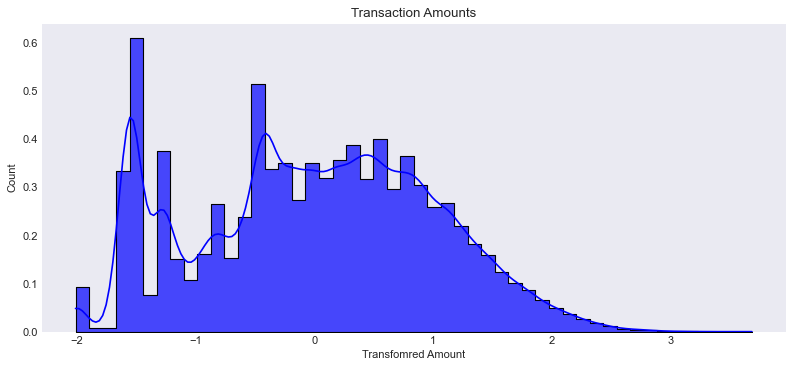

In [42]:
# plot the histogram of a variable from the dataset again to see the result
# plotting
plt.figure(figsize=(12,5), dpi=80)
sns.histplot(X_train['transfomred_Amount'], bins=50, color='blue', edgecolor='black', alpha=0.7, element='step', stat='density', common_norm=False, kde=True)
plt.xlabel('Transfomred Amount')
plt.ylabel('Count')
plt.title('Transaction Amounts')

Text(0.5, 1.0, 'Transaction Amounts')

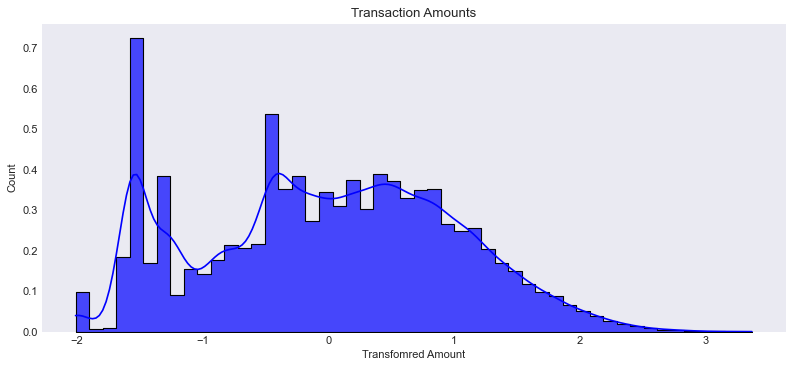

In [43]:
# plot the histogram of a variable from the dataset again to see the result
# plotting
plt.figure(figsize=(12,5), dpi=80)
sns.histplot(X_test['transfomred_Amount'], bins=50, color='blue', edgecolor='black', alpha=0.7, element='step', stat='density', common_norm=False, kde=True)
plt.xlabel('Transfomred Amount')
plt.ylabel('Count')
plt.title('Transaction Amounts')

In [44]:
# Standardizing Amount feature
sc = StandardScaler()
X_train['scaledAmount'] = sc.fit_transform(X_train[['transfomred_Amount']])
X_test['scaledAmount'] = sc.transform(X_test[['transfomred_Amount']])

<Axes: >

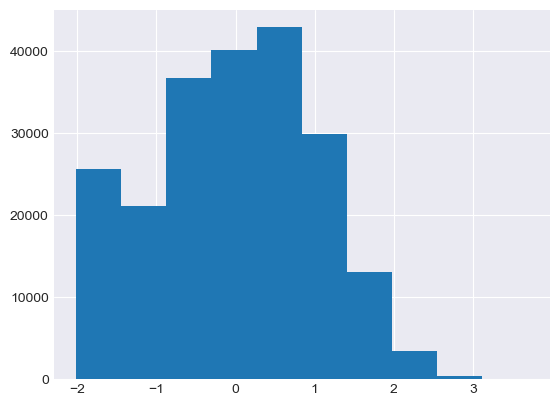

In [45]:
X_train['scaledAmount'].hist()

In [46]:
#removing Amount and transfomred_amount
X_train = X_train.drop(['Amount','transfomred_Amount','Time_hr'], axis=1)
X_test = X_test.drop(['Amount','transfomred_Amount','Time_hr'], axis=1)

In [47]:
X_train.columns

Index(['V1', 'V2', 'V3', 'V4', 'V7', 'V9', 'V10', 'V11', 'V12', 'V14', 'V16',
       'V17', 'V18', 'V19', 'V27', 'scaledAmount'],
      dtype='object')

In [48]:
X_train.head()

,V1,V2,V3,V4,V7,V9,V10,V11,V12,V14,V16,V17,V18,V19,V27,scaledAmount
17884,-0.840333,-0.526032,1.730303,-0.808008,0.056146,0.525878,-0.905381,0.329336,1.038813,-0.514504,0.333716,-0.547176,0.093876,0.238069,0.073129,0.947209
232246,-3.756704,-0.853465,-0.449739,-2.423920,0.123247,0.962507,-1.103336,-0.023132,0.507055,0.324608,1.423536,-1.248222,0.866346,-0.452917,-0.862160,1.077585
208554,-2.021166,1.590508,-0.539136,-1.551936,-1.103548,0.720191,-1.451599,-1.609796,0.425411,-1.590375,0.655528,0.579286,0.127909,-0.933770,0.543648,1.044909
11464,1.377495,-0.437941,0.643866,-0.243826,-0.600576,0.776010,0.103307,0.424536,-2.612572,0.884224,0.529134,1.386995,-1.545854,0.731178,-0.011904,-0.029545
109718,-0.365864,1.084303,1.232877,0.867853,0.747583,-0.492603,-0.008579,-0.565222,-0.265531,0.369115,-0.321379,-0.174675,0.141157,0.402857,0.412181,-0.482898


### Model Building with Random Oversampling
- Build different models on the imbalanced dataset and see the result

In [101]:
# Logistic Regression
# from sklearn.linear_model import LogisticRegression #import the package

num_C = [0.01, 0.1, 1, 10, 100]  #--> list of values
cv_num = 5  #--> list of values

lr = LogisticRegression()

In [102]:
# Create a dictionary of hyperparameters to tune
param_grid = {'C': num_C } # Regularization strength
cv = StratifiedKFold(n_splits=cv_num, shuffle=True, random_state=42)

# Define the scoring metrics you want to evaluate
scoring = ['accuracy', 'precision', 'recall', 'f1']

#### perfom cross validation on the X_train & y_train to create:
- X_train_cv
- X_test_cv
- y_train_cv
- y_test_cv

In [51]:
#perform cross validation
grid_searchlr = GridSearchCV(estimator=lr, param_grid=param_grid, cv=cv, scoring=scoring,n_jobs=-1, verbose=1, return_train_score=True, refit='f1')
start = time.time()
#perform hyperparameter tuning
grid_searchlr.fit(X_train, y_train)
end = time.time()
delta = end-start

print('Time taken:',delta/3600)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Time taken: 0.0014934523900349934


In [52]:
#print the evaluation result by choosing a evaluation metric
best_score = grid_searchlr.best_score_
print(f"Best F1-Score from cross-validation: {best_score:.4f}")

#print the optimum value of hyperparameters
best_params = grid_searchlr.best_params_
print(f"Optimum hyperparameters: {best_params}")

Best F1-Score from cross-validation: 0.7333
Optimum hyperparameters: {'C': 0.1}


In [53]:
# Print the best cross-validated scores for each metric
# Get the best estimator
best_model = grid_searchlr.best_estimator_
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchlr.cv_results_['mean_test_accuracy'][grid_searchlr.best_index_]:.4f}")
print(f"Precision: {grid_searchlr.cv_results_['mean_test_precision'][grid_searchlr.best_index_]:.4f}")
print(f"Recall:    {grid_searchlr.cv_results_['mean_test_recall'][grid_searchlr.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchlr.cv_results_['mean_test_f1'][grid_searchlr.best_index_]:.4f}")

# # Predict and evaluate on the test set
# y_pred = best_model.predict(X_test)
# print(classification_report(y_test, y_pred))

Best cross-validated scores for each metric:
Accuracy:  0.9992
Precision: 0.8906
Recall:    0.6289
F1-Score:  0.7333


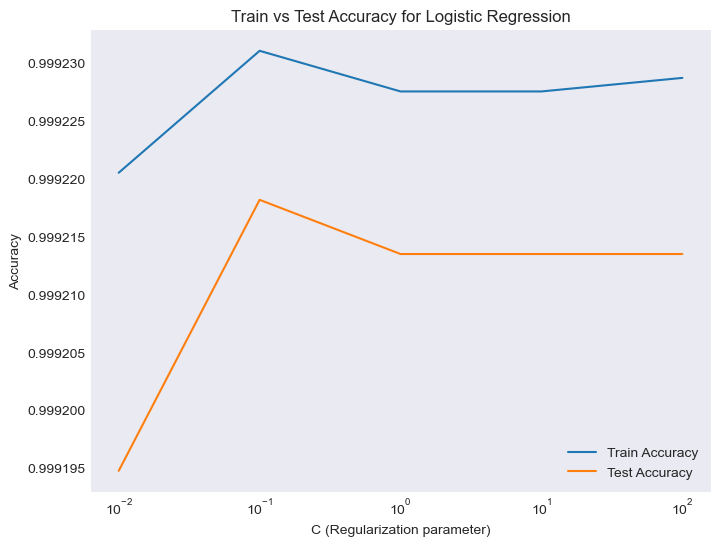

In [54]:
# Extract train and test scores
train_scores = grid_searchlr.cv_results_['mean_train_accuracy']
test_scores = grid_searchlr.cv_results_['mean_test_accuracy']

param_values = grid_searchlr.cv_results_['param_C'].data  # Adjust this if you are tuning a different parameter

# Plotting the results
plt.figure(figsize=(8, 6))
plt.plot(param_values, train_scores, label='Train Accuracy')
plt.plot(param_values, test_scores, label='Test Accuracy')
plt.xscale('log')
plt.xlabel('C (Regularization parameter)')
plt.ylabel('Accuracy')
plt.title('Train vs Test Accuracy for Logistic Regression')
plt.legend()
plt.show()

In [55]:
# Predict on the test set
y_pred = best_model.predict(X_test)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[71065    14]
 [   51    72]]


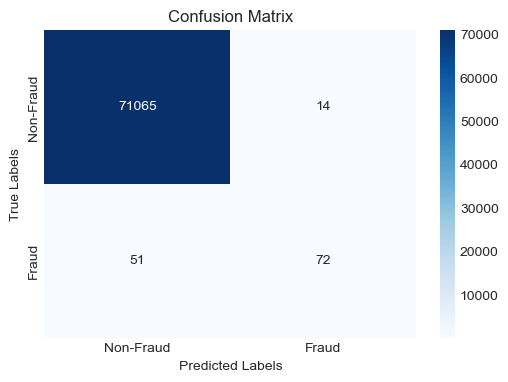

In [56]:
# Plotting the confusion matrix using seaborn
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Fraud', 'Fraud'], yticklabels=['Non-Fraud', 'Fraud'])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [57]:
# import matplotlib.pyplot as plt
# from sklearn.metrics import roc_curve, auc

# # Predict probabilities for the positive class
# y_probs = best_model.predict_proba(X_test)[:, 1]

# # Calculate ROC curve and ROC-AUC
# fpr, tpr, thresholds = roc_curve(y_test, y_probs)
# roc_auc = auc(fpr, tpr)

# # Plot the ROC curve
# plt.figure(figsize=(8, 6))
# plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
# plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')  # Diagonal line
# plt.xlim([0.0, 1.0])
# plt.ylim([0.0, 1.05])
# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.title('Receiver Operating Characteristic (ROC) Curve')
# plt.legend(loc='lower right')
# plt.grid()
# plt.show()

### Similarly explore other algorithms by building models like:
- KNN
- SVM
- Decision Tree
- Random Forest
- XGBoost

## KNN

In [58]:
# from sklearn.neighbors import KNeighborsClassifier

# Initialize KNN model
knn = KNeighborsClassifier()

In [59]:
# Define the hyperparameter grid
param_grid = {
    'n_neighbors': [3, 5, 7, 10, 15, 20],  # Number of neighbors to use
    #'weights': ['uniform', 'distance'],    # Weight function used in prediction
    #'p': [1, 2]                            # Power parameter for the Minkowski distance
    }

In [61]:
# Perform GridSearchCV with multiple scoring metrics
grid_searchknn = GridSearchCV(estimator=knn, param_grid=param_grid, cv=cv, scoring=scoring,n_jobs= -1, return_train_score=True, refit='f1')

start = time.time()
# Fit the model
grid_searchknn.fit(X_train, y_train)
end = time.time()
delta = end - start
print('time taken',delta/3600)

time taken 0.2393752106030782


In [62]:
# Get the best estimator
best_knn = grid_searchknn.cv_results_

# Print the best cross-validated scores for each metric
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchknn.cv_results_['mean_test_accuracy'][grid_searchknn.best_index_]:.4f}")
print(f"Precision: {grid_searchknn.cv_results_['mean_test_precision'][grid_searchknn.best_index_]:.4f}")
print(f"Recall:    {grid_searchknn.cv_results_['mean_test_recall'][grid_searchknn.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchknn.cv_results_['mean_test_f1'][grid_searchknn.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9995
Precision: 0.9257
Recall:    0.7995
F1-Score:  0.8577


In [75]:
grid_searchknn.cv_results_['param_n_neighbors'].data

array([ 3,  5,  7, 10, 15, 20])

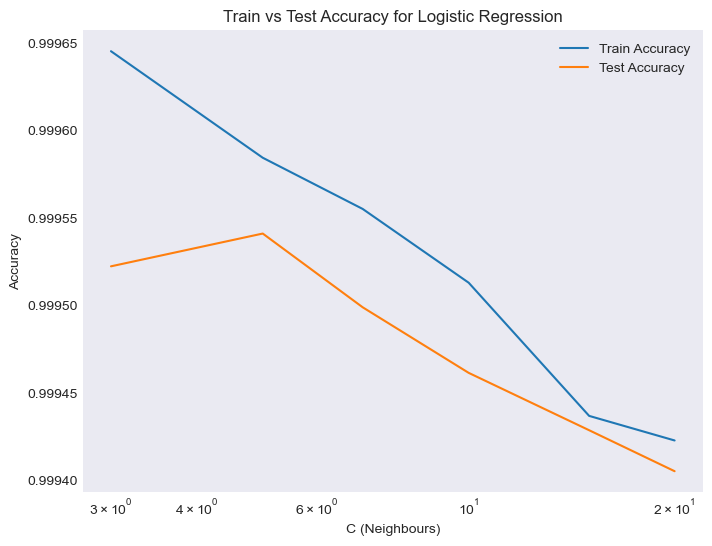

In [81]:
# Extract train and test scores
train_scores = grid_searchknn.cv_results_['mean_train_accuracy']
test_scores = grid_searchknn.cv_results_['mean_test_accuracy']

param_values = grid_searchknn.cv_results_['param_n_neighbors'].data  # Adjust this if you are tuning a different parameter

# Plotting the results
plt.figure(figsize=(8, 6))
plt.plot(param_values, train_scores, label='Train Accuracy')
plt.plot(param_values, test_scores, label='Test Accuracy')
plt.xscale('log')
plt.xlabel('C (Neighbours)')
plt.ylabel('Accuracy')
plt.title('Train vs Test Accuracy for Logistic Regression')
plt.legend()
plt.show()

### SVM

In [51]:
from sklearn.svm import SVC

# Initialize the SVM model
svm = SVC()

In [52]:

param_grid = {
    'C': [0.001, 0.1, 1.0, 10, 100],          # Regularization parameter
    'kernel': ['linear', 'rbf'],      # Kernel type: linear, RBF (Gaussian)
    'gamma': ['scale', 'auto'],       # Kernel coefficient for 'rbf', 'poly' and 'sigmoid'
}

In [53]:
grid_search = GridSearchCV(estimator=svm, param_grid=param_grid, cv=5, scoring=scoring, return_train_score=True ,refit='f1',n_jobs= -1)

start = time.time()
# Fit the model
grid_search.fit(X_train, y_train)
end = time.time()
delta = end - start
print('time taken',delta/3600)

# Get the best estimator
best_svm = grid_search.best_estimator_

time taken 7.524375394715203


In [54]:
# Print the best cross-validated scores for each metric
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_search.cv_results_['mean_test_accuracy'][grid_search.best_index_]:.4f}")
print(f"Precision: {grid_search.cv_results_['mean_test_precision'][grid_search.best_index_]:.4f}")
print(f"Recall:    {grid_search.cv_results_['mean_test_recall'][grid_search.best_index_]:.4f}")
print(f"F1-Score:  {grid_search.cv_results_['mean_test_f1'][grid_search.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9995
Precision: 0.9507
Recall:    0.7289
F1-Score:  0.8247


### Decission Tree

In [77]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree model
dt = DecisionTreeClassifier()

In [78]:
param_grid = {
    'criterion': ['gini', 'entropy'],       # The function to measure the quality of a split
    'max_depth': [None, 10, 20, 30, 40],    # The maximum depth of the tree
    'min_samples_split': [2, 10, 20],       # The minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 5, 10],         # The minimum number of samples required to be at a leaf node
    'max_features': [None, 'sqrt', 'log2']  # The number of features to consider when looking for the best split
}

In [82]:
grid_searchdt = GridSearchCV(estimator=dt, param_grid=param_grid, n_jobs= -1, cv=cv, scoring=scoring, return_train_score=True ,refit='f1', verbose=True)

start = time.time()
# Fit the model
grid_searchdt.fit(X_train, y_train)
end = time.time()
delta = end - start
print('time taken',delta/3600)

Fitting 5 folds for each of 270 candidates, totalling 1350 fits
time taken 0.18564137670728895


In [83]:
# Get the best estimator
best_dt = grid_searchdt.best_estimator_

# Print the best cross-validated scores for each metric
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchdt.cv_results_['mean_test_accuracy'][grid_searchdt.best_index_]:.4f}")
print(f"Precision: {grid_searchdt.cv_results_['mean_test_precision'][grid_searchdt.best_index_]:.4f}")
print(f"Recall:    {grid_searchdt.cv_results_['mean_test_recall'][grid_searchdt.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchdt.cv_results_['mean_test_f1'][grid_searchdt.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9994
Precision: 0.8970
Recall:    0.7588
F1-Score:  0.8199


### Random Forest

In [85]:
# from sklearn.ensemble import RandomForestClassifier


# Initialize the Random Forest model
rf = RandomForestClassifier(random_state=42)

In [86]:
# Define the hyperparameter grid
param_grid = {
    'n_estimators': [3, 5, 10],               # Number of trees in the forest
    'max_depth': [None, 3, 5, 10],               # The maximum depth of the tree
    'min_samples_split': [2, 10, 20],              # The minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 5, 10],                # The minimum number of samples required to be at a leaf node
    'max_features': ['sqrt', 'log2', None],        # The number of features to consider when looking for the best split
    'bootstrap': [True, False]                     # Whether bootstrap samples are used when building tree
            }

In [87]:
grid_searchrf = GridSearchCV(estimator=rf, param_grid=param_grid, n_jobs= -1, cv=cv, scoring=scoring, return_train_score=True ,refit='f1')

start = time.time()
# Fit the model
grid_searchrf.fit(X_train, y_train)
end = time.time()
delta = end - start
print('time taken:',delta/3600)

time taken: 1.5416251227590774


In [88]:
# Get the best estimator
best_rf = grid_searchrf.best_estimator_

# Print the best cross-validated scores for each metric
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchrf.cv_results_['mean_test_accuracy'][grid_searchrf.best_index_]:.4f}")
print(f"Precision: {grid_searchrf.cv_results_['mean_test_precision'][grid_searchrf.best_index_]:.4f}")
print(f"Recall:    {grid_searchrf.cv_results_['mean_test_recall'][grid_searchrf.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchrf.cv_results_['mean_test_f1'][grid_searchrf.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9995
Precision: 0.9297
Recall:    0.7724
F1-Score:  0.8430


### XGBoost

In [89]:
# from xgboost import XGBClassifier

# Initialize the XGBoost model
xgb = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')

In [90]:
# Define the hyperparameter grid
param_grid = {
    'n_estimators': [100, 200, 300],            # Number of boosting rounds
    'learning_rate': [0.01, 0.1, 0.2],          # Step size shrinkage
    'max_depth': [3, 6, 9],                     # Maximum depth of a tree
    'min_child_weight': [1, 5, 10],             # Minimum sum of instance weight (hessian) needed in a child
    'subsample': [0.8, 1.0],                    # Subsample ratio of the training instances
    'colsample_bytree': [0.8, 1.0],             # Subsample ratio of columns when constructing each tree
    'gamma': [0, 0.1, 0.2]                      # Minimum loss reduction required to make a further partition on a leaf node
}

In [91]:
grid_searchxgb = GridSearchCV(estimator=xgb, param_grid=param_grid, cv=cv, scoring=scoring, refit='f1', n_jobs=-1,return_train_score=True)


start = time.time()
# Fit the model
grid_searchxgb.fit(X_train, y_train)
end = time.time()

delta = end-start
print('Time taken for execution:', delta/3600)

/Users/binayyadab/anaconda3/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [14:32:27] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [14:32:27] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [14:32:27] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [14:32:27] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, U

Time taken for execution: 0.8032569499810537


In [93]:
# Get the best estimator
best_xgb = grid_searchxgb.best_estimator_

# Print the best cross-validated scores for each metric
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchxgb.cv_results_['mean_test_accuracy'][grid_searchxgb.best_index_]:.4f}")
print(f"Precision: {grid_searchxgb.cv_results_['mean_test_precision'][grid_searchxgb.best_index_]:.4f}")
print(f"Recall:    {grid_searchxgb.cv_results_['mean_test_recall'][grid_searchxgb.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchxgb.cv_results_['mean_test_f1'][grid_searchxgb.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9996
Precision: 0.9434
Recall:    0.8021
F1-Score:  0.8666


In [94]:
print(best_xgb)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=0, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=1, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=None, num_parallel_tree=None, random_state=42, ...)


#### from all the models we can obserev that XGBoost has the best performance with F1 score of 87%

#### Proceed with the model which shows the best result
- Apply the best hyperparameter on the model
- Predict on the test dataset

In [304]:
# Initialize the XGBoost model with the best hyperparameters
clfxgb = XGBClassifier(
    colsample_bytree=0.8,
    eval_metric='logloss',
    learning_rate=0.1,
    max_depth=6,
    min_child_weight=1,
    n_estimators=300,
    random_state=42
)

start = time.time()
# Fit the model to the training data
clfxgb.fit(X_train, y_train)
end = time.time()
print('Time taken: ', (end-start)/3600)

# Evaluate the model on the test dataset using F1-Score
from sklearn.metrics import f1_score

y_pred = clf.predict(X_test)
f1 = f1_score(y_test, y_pred)
print(f"F1-Score on the test dataset: {f1:.4f}")

Time taken:  0.0003811780611673991
F1-Score on the test dataset: 0.8520


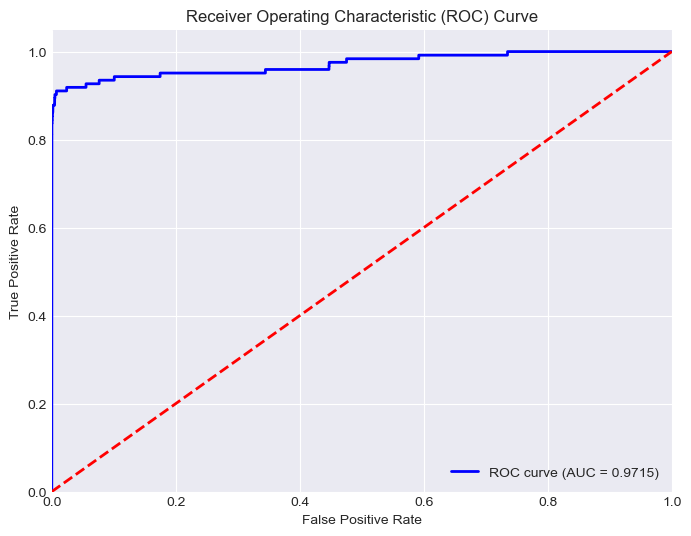

In [307]:
from sklearn.metrics import roc_curve, auc

# Predict probabilities for the positive class
y_probs = clfxgb.predict_proba(X_test)[:, 1]

# Calculate ROC curve and ROC-AUC
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')  # Diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid()
plt.show()

In [309]:
y_pred = clf.predict(X_test)
cnf = confusion_matrix(y_test, y_pred)
print('Confusion matrix:\n',cnf)

Confusion matrix:
 [[71074     5]
 [   28    95]]


In [ ]:
# clf = ___  #initialise the model with optimum hyperparameters
# clf.fit(X_train, y_train)
# print --> #print the evaluation score on the X_test by choosing the best evaluation metric

### Print the important features of the best model to understand the dataset
- This will not give much explanation on the already transformed dataset
- But it will help us in understanding if the dataset is not PCA transformed

Top var = 10
2nd Top var = 7
3rd Top var = 9


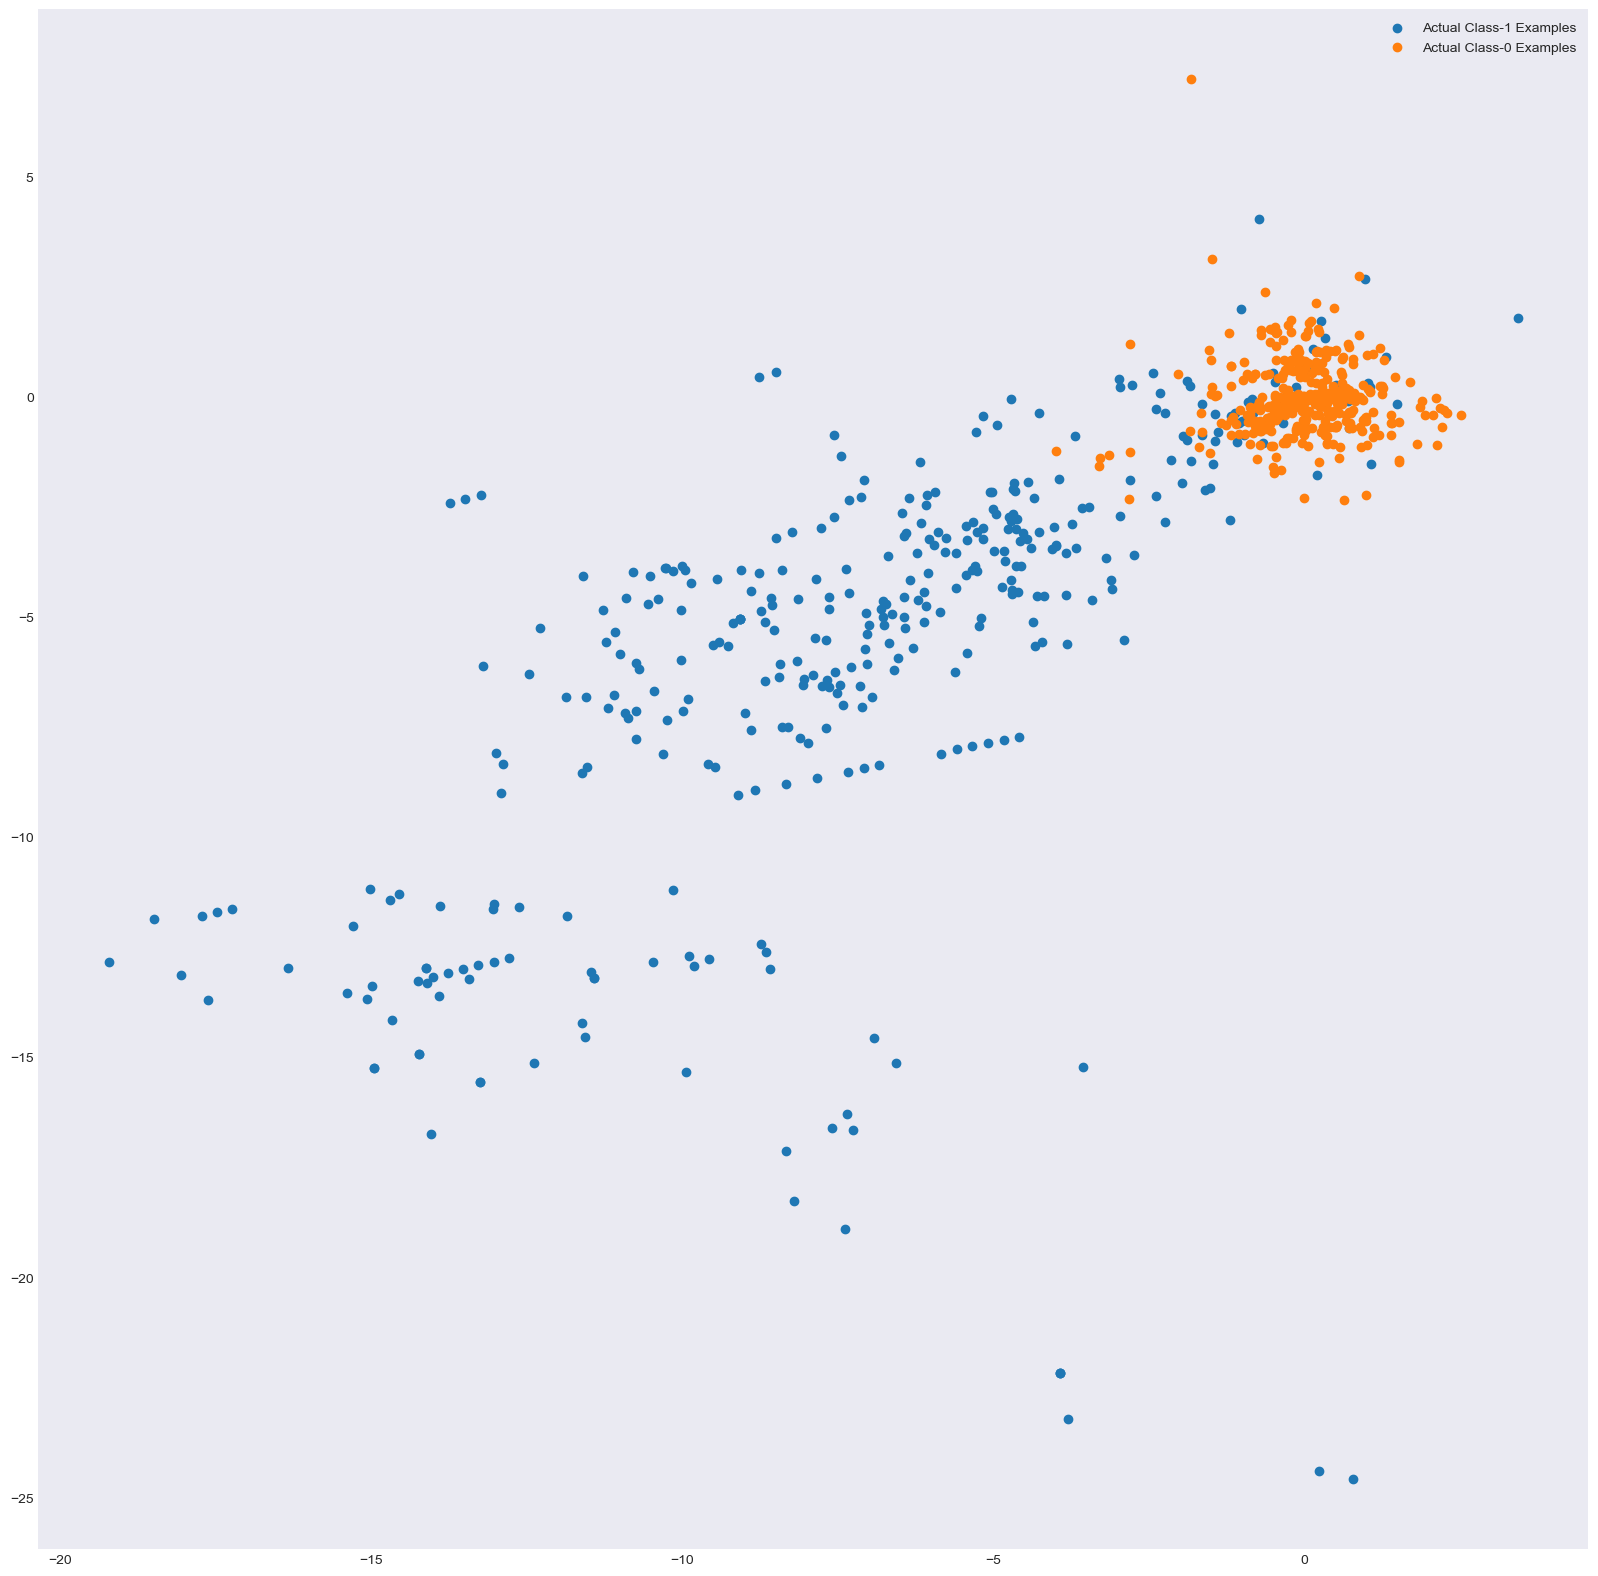

In [96]:
var_imp = []
for i in clf.feature_importances_:
    var_imp.append(i)
print('Top var =', var_imp.index(np.sort(clf.feature_importances_)[-1])+1)
print('2nd Top var =', var_imp.index(np.sort(clf.feature_importances_)[-2])+1)
print('3rd Top var =', var_imp.index(np.sort(clf.feature_importances_)[-3])+1)

# Variable on Index-16 and Index-13 seems to be the top 2 variables
top_var_index = var_imp.index(np.sort(clf.feature_importances_)[-1])
second_top_var_index = var_imp.index(np.sort(clf.feature_importances_)[-2])

X_train_1 = X_train.to_numpy()[np.where(y_train==1.0)]
X_train_0 = X_train.to_numpy()[np.where(y_train==0.0)]

np.random.shuffle(X_train_0)

import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = [20, 20]

plt.scatter(X_train_1[:, top_var_index], X_train_1[:, second_top_var_index], label='Actual Class-1 Examples')
plt.scatter(X_train_0[:X_train_1.shape[0], top_var_index], X_train_0[:X_train_1.shape[0], second_top_var_index],
            label='Actual Class-0 Examples')
plt.legend()
plt.show()

## Model building with balancing Classes

##### Perform class balancing with :
- Random Oversampling
- SMOTE
- ADASYN

### Model Building with Random Oversampling
- Build different models on the balanced dataset and see the result

In [97]:
# pip install --upgrade scikit-learn imbalanced-learn

In [54]:
# from sklearn import linear_model

In [169]:
# Initialize Logistic Regression model
lr = LogisticRegression(solver='liblinear')

In [170]:
# Create a pipeline with RandomOverSampler and LogisticRegression
pipeline = Pipeline([
    ('oversample', RandomOverSampler(random_state=42)),
    ('lr', lr)
])

In [171]:
num_C = num_C = [0.001, 0.01, 0.1, 1, 10, 100]  #--> list of values
cv_num =  5 #--> list of values

# Define the parameter grid
param_grid = {'lr__C': num_C}
cv = StratifiedKFold(n_splits=cv_num, shuffle=True, random_state=42)

#### perfom cross validation on the X_train & y_train to create:
- X_train_cv
- X_test_cv
- y_train_cv
- y_test_cv

In [174]:
# Perform grid search cross-validation with RandomOversampling
grid_searchlr2 = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv, n_jobs=-1, verbose=1, refit='f1', return_train_score=True)
start = time.time()
grid_searchlr2.fit(X_train, y_train)
end = time.time()
delta = end - start
print('Time taken:', delta/3600)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Time taken: 0.0030903505616717867


In [175]:
# Print the best evaluation score
print(f"Best F1-Score from cross-validation: {grid_searchlr2.best_score_:.4f}")

# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchlr2.best_params_}")

Best F1-Score from cross-validation: 0.1170
Best hyperparameters: {'lr__C': 0.001}


In [176]:
# Print the best cross-validated scores for each metric
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchlr2.cv_results_['mean_test_accuracy'][grid_searchlr2.best_index_]:.4f}")
print(f"Precision: {grid_searchlr2.cv_results_['mean_test_precision'][grid_searchlr2.best_index_]:.4f}")
print(f"Recall:    {grid_searchlr2.cv_results_['mean_test_recall'][grid_searchlr2.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchlr2.cv_results_['mean_test_f1'][grid_searchlr2.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9763
Precision: 0.0626
Recall:    0.9024
F1-Score:  0.1170


### Similarly explore other algorithms on balanced dataset by building models like:
- KNN
- SVM
- Decision Tree
- Random Forest
- XGBoost

### KNN

In [112]:
# from sklearn.neighbors import KNeighborsClassifier

# Define the model
knn = KNeighborsClassifier()

In [113]:
num_neighbors = [3, 5, 7, 9, 11] 
# Create a pipeline with RandomOverSampler and KNN
pipeline = Pipeline([
    ('oversample', RandomOverSampler(random_state=42)),
    ('knn', knn)
])
# Define the parameter grid
param_grid = {'knn__n_neighbors': num_neighbors}

In [116]:
# Perform grid search cross-validation with RandomOversampling
grid_searchknn2 = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv, n_jobs=-1, verbose=1, return_train_score=True, refit='f1')
grid_searchknn2.fit(X_train, y_train)

Fitting 5 folds for each of 5 candidates, totalling 25 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('oversample',
                                        RandomOverSampler(random_state=42)),
                                       ('knn', KNeighborsClassifier())]),
             n_jobs=-1, param_grid={'knn__n_neighbors': [3, 5, 7, 9, 11]},
             refit='f1', return_train_score=True,
             scoring=['accuracy', 'precision', 'recall', 'f1'], verbose=1)

In [118]:
# Print the best evaluation score
print(f"Best F1-Score from cross-validation: {grid_searchknn2.best_score_:.4f}")

# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchknn2.best_params_}")

Best F1-Score from cross-validation: 0.7931
Best hyperparameters: {'knn__n_neighbors': 3}


In [117]:
# Print the best cross-validated scores for each metric
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchknn2.cv_results_['mean_test_accuracy'][grid_searchknn2.best_index_]:.4f}")
print(f"Precision: {grid_searchknn2.cv_results_['mean_test_precision'][grid_searchknn2.best_index_]:.4f}")
print(f"Recall:    {grid_searchknn2.cv_results_['mean_test_recall'][grid_searchknn2.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchknn2.cv_results_['mean_test_f1'][grid_searchknn2.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9993
Precision: 0.7692
Recall:    0.8238
F1-Score:  0.7931


### XGBoost

In [126]:
# from xgboost import XGBClassifier


xgb = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
# Define the hyperparameter grid
param_grid = {
    'xgb__n_estimators': [100, 200, 300],            # Number of boosting rounds
    'xgb__learning_rate': [0.01, 0.1, 0.2],          # Step size shrinkage
    'xgb__max_depth': [3, 6, 9],                     # Maximum depth of a tree
    'xgb__min_child_weight': [1, 5, 10],             # Minimum sum of instance weight (hessian) needed in a child
    'xgb__subsample': [0.8, 1.0],                    # Subsample ratio of the training instances
    'xgb__colsample_bytree': [0.8, 1.0],             # Subsample ratio of columns when constructing each tree
    'xgb__gamma': [0, 0.1, 0.2]                      # Minimum loss reduction required to make a further partition on a leaf node
}


# Create a pipeline with RandomOverSampler and XGBoost
pipeline = Pipeline([
    ('oversample', RandomOverSampler(random_state=42)),
    ('xgb', xgb)
])

In [127]:
# Perform grid search cross-validation with RandomOversampling
grid_searchxgb2 = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv_num, n_jobs=-1, verbose=1, return_train_score=True, refit='f1')
grid_searchxgb2.fit(X_train, y_train)

Fitting 5 folds for each of 972 candidates, totalling 4860 fits


/Users/binayyadab/anaconda3/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [17:45:31] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [17:45:31] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [17:45:32] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [17:45:32] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, U

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('oversample',
                                        RandomOverSampler(random_state=42)),
                                       ('xgb',
                                        XGBClassifier(base_score=None,
                                                      booster=None,
                                                      callbacks=None,
                                                      colsample_bylevel=None,
                                                      colsample_bynode=None,
                                                      colsample_bytree=None,
                                                      device=None,
                                                      early_stopping_rounds=None,
                                                      enable_categorical=False,
                                                      eval_metric='logloss',
                                                      feature_types=None,
                                                      gamma=None,
                                                      grow_pol...
                                                      random_state=42, ...))]),
             n_jobs=-1,
             param_grid={'xgb__colsample_bytree': [0.8, 1.0],
                         'xgb__gamma': [0, 0.1, 0.2],
                         'xgb__learning_rate': [0.01, 0.1, 0.2],
                         'xgb__max_depth': [3, 6, 9],
                         'xgb__min_child_weight': [1, 5, 10],
                         'xgb__n_estimators': [100, 200, 300],
                         'xgb__subsample': [0.8, 1.0]},
             refit='f1', return_train_score=True,
             scoring=['accuracy', 'precision', 'recall', 'f1'], verbose=1)

In [128]:
# Print the best evaluation score
print(f"Best F1-Score from cross-validation: {grid_searchxgb2.best_score_:.4f}")

# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchxgb2.best_params_}")

# Print the best number of estimators
print(f"Best number of estimators: {grid_searchxgb2.best_params_['xgb__n_estimators']}")

Best F1-Score from cross-validation: 0.8617
Best hyperparameters: {'xgb__colsample_bytree': 0.8, 'xgb__gamma': 0, 'xgb__learning_rate': 0.2, 'xgb__max_depth': 6, 'xgb__min_child_weight': 1, 'xgb__n_estimators': 200, 'xgb__subsample': 0.8}
Best number of estimators: 200


In [129]:
# Print the best cross-validated scores for each metric
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchxgb2.cv_results_['mean_test_accuracy'][grid_searchxgb2.best_index_]:.4f}")
print(f"Precision: {grid_searchxgb2.cv_results_['mean_test_precision'][grid_searchxgb2.best_index_]:.4f}")
print(f"Recall:    {grid_searchxgb2.cv_results_['mean_test_recall'][grid_searchxgb2.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchxgb2.cv_results_['mean_test_f1'][grid_searchxgb2.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9995
Precision: 0.8975
Recall:    0.8293
F1-Score:  0.8617


### Random Forest

In [274]:
# Define the Random Forest model
rf = RandomForestClassifier(random_state=42)


#definr parameters
#definr parameters
n_estimators= [25, 50,100,150]                  # Number of trees in the forest             
max_depths=[None, 3, 5, 10]                        # The maximum depth of the tree
min_samples_split = [2, 10, 20]                    # The minimum number of samples required to split an internal node

# Define the parameter grid
param_grid = {
    'rf__n_estimators': n_estimators,
    'rf__max_depth': max_depths,
    'rf__min_samples_split': min_samples_split
}


# Create a pipeline with RandomOverSampler and Random Forest
pipeline = Pipeline([
    ('oversample', RandomOverSampler(random_state=42)),
    ('rf', rf)
])

In [275]:
import time
# Perform grid search cross-validation with RandomOversampling
grid_searchrf2 = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv_num, n_jobs=-1, verbose=1, return_train_score=True, refit='f1')
start = time.time()
grid_searchrf2.fit(X_train, y_train)
end = time.time()
delta = end-start
print('Time taken:',delta/3600)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Time taken: 0.6461126828193664


In [276]:
# Print the best evaluation score
print(f"Best F1-Score from cross-validation: {grid_searchrf2.best_score_:.4f}")

# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchrf2.best_params_}")
# Print the best number of estimators
print(f"Best number of estimators: {grid_searchrf2.best_params_['rf__n_estimators']}")

Best F1-Score from cross-validation: 0.8541
Best hyperparameters: {'rf__max_depth': None, 'rf__min_samples_split': 2, 'rf__n_estimators': 150}
Best number of estimators: 150


In [277]:
# Print the best cross-validated scores for each metric
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchrf2.cv_results_['mean_test_accuracy'][grid_searchrf2.best_index_]:.4f}")
print(f"Precision: {grid_searchrf2.cv_results_['mean_test_precision'][grid_searchrf2.best_index_]:.4f}")
print(f"Recall:    {grid_searchrf2.cv_results_['mean_test_recall'][grid_searchrf2.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchrf2.cv_results_['mean_test_f1'][grid_searchrf2.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9995
Precision: 0.9256
Recall:    0.7939
F1-Score:  0.8541


### Print the class distribution after applying SMOTE

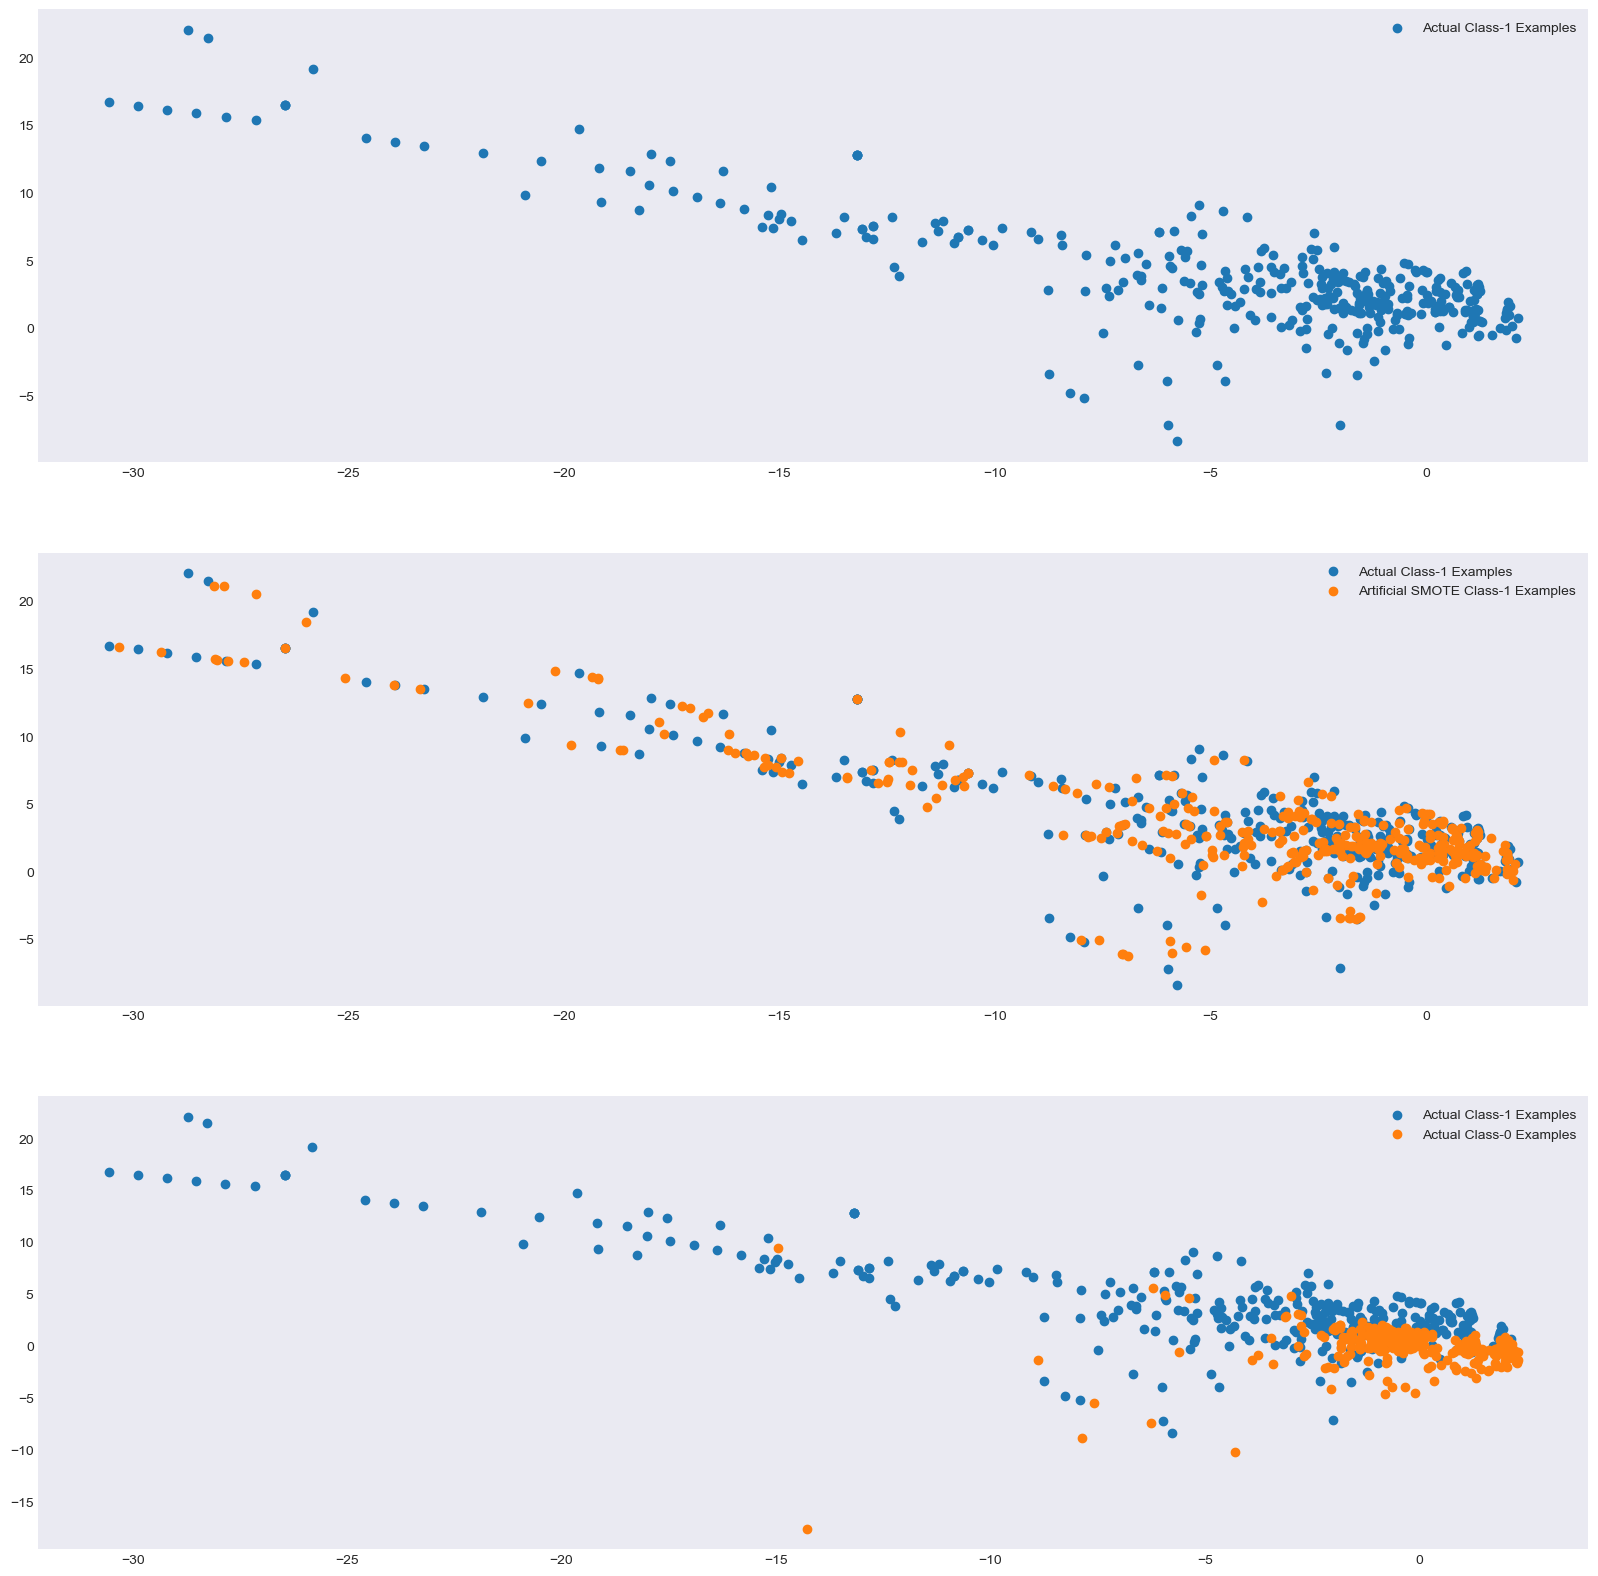

In [137]:
import warnings
warnings.filterwarnings("ignore")

# Applying SMOTE
sm = over_sampling.SMOTE(random_state=0)
X_train_smote, y_train_smote = sm.fit_resample(X_train, y_train)
# Artificial minority samples and corresponding minority labels from SMOTE are appended
# below X_train and y_train respectively
# So to exclusively get the artificial minority samples from SMOTE, we do

# Extracting artificial minority samples from SMOTE
X_train_smote_1 = X_train_smote.iloc[X_train.shape[0]:]

# Separating original class-1 and class-0 samples
X_train_1 = X_train.to_numpy()[np.where(y_train == 1.0)]
X_train_0 = X_train.to_numpy()[np.where(y_train == 0.0)]

# Plotting
plt.rcParams['figure.figsize'] = [20, 20]
fig = plt.figure()

plt.subplot(3, 1, 1)
plt.scatter(X_train_1[:, 0], X_train_1[:, 1], label='Actual Class-1 Examples')
plt.legend()

plt.subplot(3, 1, 2)
plt.scatter(X_train_1[:, 0], X_train_1[:, 1], label='Actual Class-1 Examples')
plt.scatter(X_train_smote_1.iloc[:X_train_1.shape[0], 0], X_train_smote_1.iloc[:X_train_1.shape[0], 1], 
            label='Artificial SMOTE Class-1 Examples')
plt.legend()

plt.subplot(3, 1, 3)
plt.scatter(X_train_1[:, 0], X_train_1[:, 1], label='Actual Class-1 Examples')
plt.scatter(X_train_0[:X_train_1.shape[0], 0], X_train_0[:X_train_1.shape[0], 1], label='Actual Class-0 Examples')
plt.legend()

plt.show()

In [ ]:
#perform cross validation & then balance classes on X_train_cv & y_train_cv using SMOTE

#perform hyperparameter tuning

#print the evaluation result by choosing a evaluation metric

#print the optimum value of hyperparameters


### Modeling after applying SMOTE

### XGBoost

In [138]:
# from xgboost import XGBClassifier

# Define the XGBoost model
xgb = XGBClassifier(random_state=42)

# Hyperparameters to tune
num_estimators = [300, 400, 500,600,700]  # Number of boosting rounds
max_depths = [3, 5, 6, 7, 8]  # Maximum depth of trees
learning_rates = [0.01, 0.1, 0.2]  # Learning rates

# Create a pipeline with RandomOverSampler and XGBoost
pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('xgb', xgb)
])

# Define the parameter grid
param_grid = {
    'xgb__n_estimators': num_estimators,
    'xgb__max_depth': max_depths,
    'xgb__learning_rate': learning_rates
}

In [144]:
# Perform grid search cross-validation with RandomOversampling

grid_searchxgb3 = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv, n_jobs=-1, verbose=1, return_train_score=True, refit='f1')
start = time.time()
grid_searchxgb3.fit(X_train, y_train)
end = time.time()

delta = end-start

print('Time taken:',delta/3600)



Fitting 5 folds for each of 75 candidates, totalling 375 fits
Time taken: 0.37078002724382614


In [145]:
# Print the best evaluation score
print(f"Best F1-Score from cross-validation: {grid_searchxgb3.best_score_:.4f}")

# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchxgb3.best_params_}")

# Print the best number of estimators
print(f"Best number of estimators: {grid_searchxgb3 .best_params_['xgb__n_estimators']}")

Best F1-Score from cross-validation: 0.7939
Best hyperparameters: {'xgb__learning_rate': 0.2, 'xgb__max_depth': 7, 'xgb__n_estimators': 700}
Best number of estimators: 700


In [146]:
# Print the best cross-validated scores for each metric
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchxgb3.cv_results_['mean_test_accuracy'][grid_searchxgb3.best_index_]:.4f}")
print(f"Precision: {grid_searchxgb3.cv_results_['mean_test_precision'][grid_searchxgb3.best_index_]:.4f}")
print(f"Recall:    {grid_searchxgb3.cv_results_['mean_test_recall'][grid_searchxgb3.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchxgb3.cv_results_['mean_test_f1'][grid_searchxgb3.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9993
Precision: 0.7654
Recall:    0.8292
F1-Score:  0.7939


### Logistic regression

In [201]:
# Define the Logistic Regression model
lr = LogisticRegression(random_state=42, max_iter=1000)

# Create a pipeline with SMOTE and Logistic Regression
pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('lr', lr)
])

# Hyperparameters to tune
param_grid = {
    'lr__C': [0.01, 0.1, 1.0, 10, 100],  # Regularization strength
    'lr__penalty': ['l1', 'l2', 'elasticnet'],  # Norm used in penalization
    'lr__solver': ['liblinear', 'saga'],  # Algorithm to use in optimization
    'lr__l1_ratio': [0.5]  # L1 ratio (only for 'elasticnet')
}

In [206]:
# Set up GridSearchCV
grid_searchlr3 = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=5, scoring=scoring, n_jobs=-1, verbose=1, refit='f1', return_train_score=True)

# Fit the model
start = time.time()
grid_searchlr3.fit(X_train, y_train)
end = time.time()

# Calculate time taken
delta = end - start
print('Time taken:', delta / 3600)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


/Users/binayyadab/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got 

Time taken: 0.0675823802418179


In [207]:
# Print the best evaluation score
print(f"Best F1-Score from cross-validation: {grid_searchlr3.best_score_:.4f}")

# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchlr3.best_params_}")

Best F1-Score from cross-validation: 0.1064
Best hyperparameters: {'lr__C': 0.01, 'lr__l1_ratio': 0.5, 'lr__penalty': 'l1', 'lr__solver': 'liblinear'}


In [208]:
# Print the best cross-validated scores for each metric
# Get the best estimator
best_model = grid_searchlr3.best_estimator_
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchlr3.cv_results_['mean_test_accuracy'][grid_searchlr3.best_index_]:.4f}")
print(f"Precision: {grid_searchlr3.cv_results_['mean_test_precision'][grid_searchlr3.best_index_]:.4f}")
print(f"Recall:    {grid_searchlr3.cv_results_['mean_test_recall'][grid_searchlr3.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchlr3.cv_results_['mean_test_f1'][grid_searchlr3.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9737
Precision: 0.0565
Recall:    0.9053
F1-Score:  0.1064


### KNN

In [213]:
# from sklearn.neighbors import KNeighborsClassifier
# Define the model
knn = KNeighborsClassifier()

In [214]:
# Hyperparameters to tune
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11],  # Number of neighbors to use
    'knn__weights': ['uniform', 'distance'],  # Weight function used in prediction
    'knn__metric': ['euclidean', 'manhattan', 'minkowski']  # Distance metric
}

# Create a pipeline with SMOTE and KNN
pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('knn', knn)
])

In [215]:
# Perform cross-validation with SMOTE
cv_num = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_searchknn3 = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv_num, n_jobs=-1, verbose=1, refit='f1', return_train_score=True)
start = time.time()
grid_searchknn3.fit(X_train, y_train)
end = time.time()

#calculate the time taken
delta = end - start
print('Time taken: ', delta/3600)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Time taken:  4.137419138352076


In [216]:
# Print the best evaluation score
print(f"Best F1-Score from cross-validation: {grid_searchknn3.best_score_:.4f}")

# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchknn3.best_params_}")

Best F1-Score from cross-validation: 0.6428
Best hyperparameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__weights': 'distance'}


In [217]:
# Print the best cross-validated scores for each metric
# Get the best estimator
best_model = grid_searchknn3.best_estimator_
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchknn3.cv_results_['mean_test_accuracy'][grid_searchknn3.best_index_]:.4f}")
print(f"Precision: {grid_searchknn3.cv_results_['mean_test_precision'][grid_searchknn3.best_index_]:.4f}")
print(f"Recall:    {grid_searchknn3.cv_results_['mean_test_recall'][grid_searchknn3.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchknn3.cv_results_['mean_test_f1'][grid_searchknn3.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9983
Precision: 0.5154
Recall:    0.8591
F1-Score:  0.6428


### Random forest

In [278]:
# Define the Random Forest model
rf = RandomForestClassifier(random_state=42)


#definr parameters
n_estimators= [100,125,150,175]                  # Number of trees in the forest             
max_depths=[None, 3, 5, 10]                        # The maximum depth of the tree
min_samples_split = [2, 10, 20]                    # The minimum number of samples required to split an internal node

# Define the parameter grid
param_grid = {
    'rf__n_estimators': n_estimators,
    'rf__max_depth': max_depths,
    'rf__min_samples_split': min_samples_split
}


# Create a pipeline with RandomOverSampler and Random Forest
pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('rf', rf)
])

In [279]:
grid_searchrf3 = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv, n_jobs=-1, verbose=1, refit='f1', return_train_score=True)
start = time.time()
grid_searchrf3.fit(X_train, y_train)
end = time.time()
delta = end-start
print('Time taken:',delta/3600)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Time taken: 1.983459124101533


In [280]:
# Print the best evaluation score
print(f"Best F1-Score from cross-validation: {grid_searchrf3.best_score_:.4f}")

# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchrf3.best_params_}")

Best F1-Score from cross-validation: 0.8432
Best hyperparameters: {'rf__max_depth': None, 'rf__min_samples_split': 10, 'rf__n_estimators': 100}


In [281]:
# Print the best cross-validated scores for each metric
# Get the best estimator
best_model = grid_searchlr3.best_estimator_
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchrf3.cv_results_['mean_test_accuracy'][grid_searchrf3.best_index_]:.4f}")
print(f"Precision: {grid_searchrf3.cv_results_['mean_test_precision'][grid_searchrf3.best_index_]:.4f}")
print(f"Recall:    {grid_searchrf3.cv_results_['mean_test_recall'][grid_searchrf3.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchrf3.cv_results_['mean_test_f1'][grid_searchrf3.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9995
Precision: 0.8689
Recall:    0.8210
F1-Score:  0.8432


##### Build models on other algorithms to see the better performing on SMOTE

### Print the class distribution after applying ADASYN

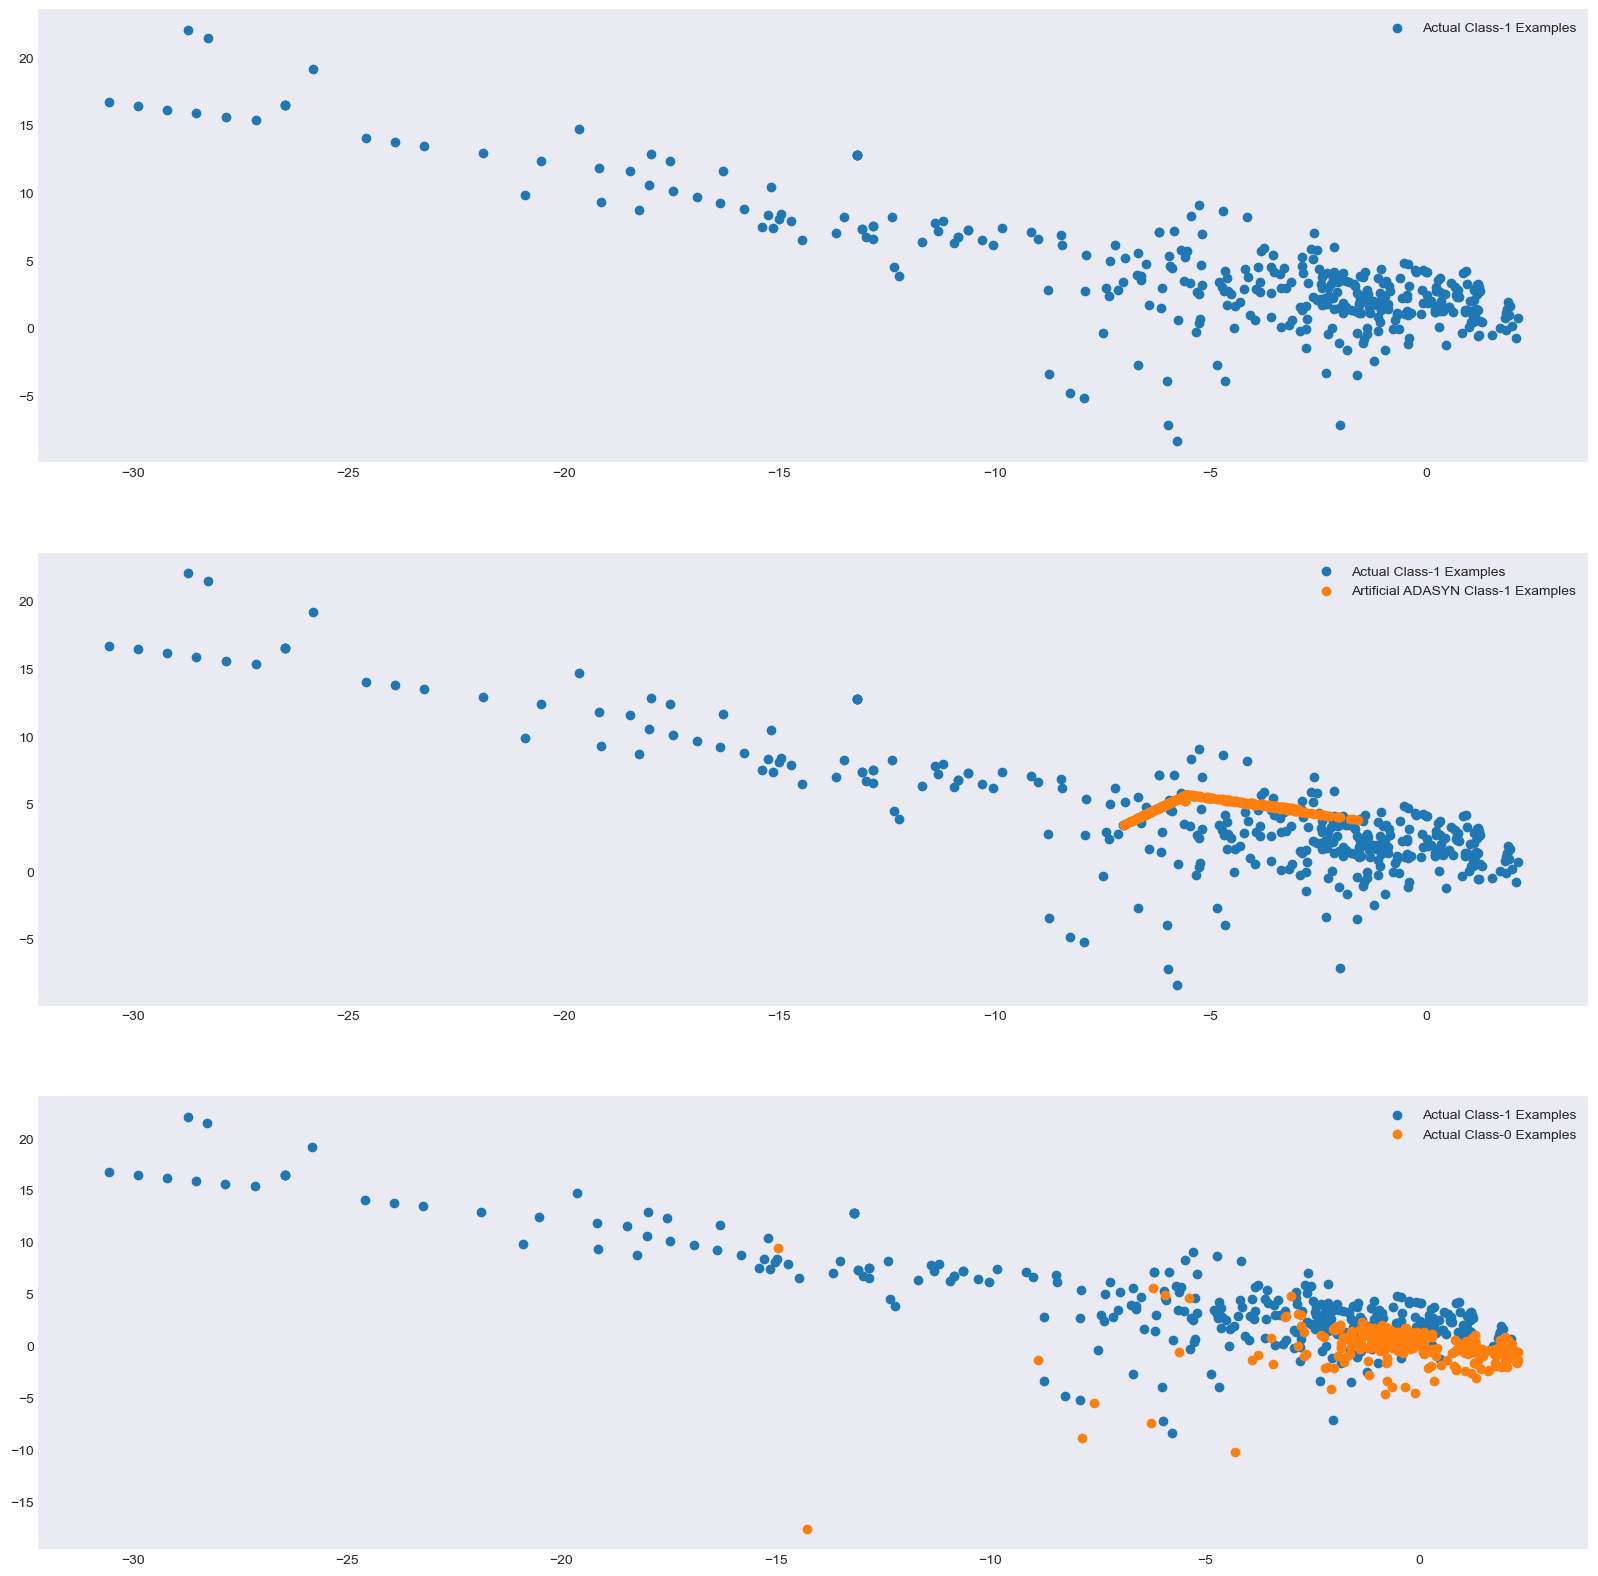

In [220]:
import warnings
warnings.filterwarnings("ignore")

from imblearn import over_sampling

ada = over_sampling.ADASYN(random_state=0, sampling_strategy='minority')
X_train_adasyn, y_train_adasyn = ada.fit_resample(X_train, y_train)
# Artificial minority samples and corresponding minority labels from ADASYN are appended
# below X_train and y_train respectively
# So to exclusively get the artificial minority samples from ADASYN, we do
X_train_adasyn_1 = X_train_adasyn[X_train.shape[0]:]

X_train_1 = X_train.to_numpy()[np.where(y_train==1.0)]
X_train_0 = X_train.to_numpy()[np.where(y_train==0.0)]



import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = [20, 20]
fig = plt.figure()

plt.subplot(3, 1, 1)
plt.scatter(X_train_1[:, 0], X_train_1[:, 1], label='Actual Class-1 Examples')
plt.legend()

plt.subplot(3, 1, 2)
plt.scatter(X_train_1[:, 0], X_train_1[:, 1], label='Actual Class-1 Examples')
plt.scatter(X_train_adasyn_1.iloc[:X_train_1.shape[0], 0], X_train_adasyn_1.iloc[:X_train_1.shape[0], 1],
            label='Artificial ADASYN Class-1 Examples')
plt.legend()

plt.subplot(3, 1, 3)
plt.scatter(X_train_1[:, 0], X_train_1[:, 1], label='Actual Class-1 Examples')
plt.scatter(X_train_0[:X_train_1.shape[0], 0], X_train_0[:X_train_1.shape[0], 1], label='Actual Class-0 Examples')
plt.legend()
plt.show()

In [ ]:
#perform cross validation & then balance classes on X_train_cv & y_train_cv using ADASYN

#perform hyperparameter tuning

#print the evaluation result by choosing a evaluation metric

#print the optimum value of hyperparameters


##### Build models on other algorithms to see the better performing on ADASYN

### Logistic Regression

In [120]:
# from imblearn.over_sampling import ADASYN

In [221]:
lr = LogisticRegression()

# Hyperparameters to tune
param_grid = {
    'lr__C': [0.01, 0.1, 1, 10, 100],  # Regularization strength
    'lr__penalty': ['l1', 'l2', 'elasticnet'],  # Norm used in penalization
    'lr__solver': ['liblinear', 'saga'],  # Algorithm to use in optimization
    'lr__l1_ratio': [0.5],  # L1 ratio (only for 'elasticnet')
}

# Create a pipeline with SMOTE and Logistic Regression
pipeline = Pipeline([
    ('adasyn', ADASYN(random_state=42)),
    ('lr', log_reg)
])


In [223]:
grid_searchlr4 = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv, n_jobs=-1, verbose=1, return_train_score=True, refit='f1')
start = time.time()
grid_searchlr4.fit(X_train, y_train)
end = time.time()
delta = end-start

print('Time taken:',delta/3600)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


/Users/binayyadab/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/Users/binayyadab/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got 

Time taken: 0.07710661550362904


In [224]:
# Print the best evaluation score
print(f"Best F1-Score from cross-validation: {grid_searchlr4.best_score_:.4f}")

# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchlr4.best_params_}")

Best F1-Score from cross-validation: 0.0314
Best hyperparameters: {'lr__C': 0.01, 'lr__l1_ratio': 0.5, 'lr__penalty': 'l2', 'lr__solver': 'saga'}


In [225]:
# Print the best cross-validated scores for each metric
# Get the best estimator
best_model = grid_searchlr4.best_estimator_
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchlr4.cv_results_['mean_test_accuracy'][grid_searchlr4.best_index_]:.4f}")
print(f"Precision: {grid_searchlr4.cv_results_['mean_test_precision'][grid_searchlr4.best_index_]:.4f}")
print(f"Recall:    {grid_searchlr4.cv_results_['mean_test_recall'][grid_searchlr4.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchlr4.cv_results_['mean_test_f1'][grid_searchlr4.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.8992
Precision: 0.0159
Recall:    0.9431
F1-Score:  0.0314


### KNN

In [228]:
# from sklearn.neighbors import KNeighborsClassifier
# Define the model
knn = KNeighborsClassifier()

In [229]:
# Hyperparameters to tune
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11],  # Number of neighbors to use
    'knn__weights': ['uniform', 'distance'],  # Weight function used in prediction
    'knn__metric': ['euclidean', 'manhattan', 'minkowski']  # Distance metric
}

# Create a pipeline with SMOTE and KNN
pipeline = Pipeline([
    ('adasyn', ADASYN(random_state=42)),
    ('knn', knn)
])

In [237]:
# Perform cross-validation with SMOTE
grid_searchknn4 = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv, n_jobs=-1, verbose=1, return_train_score=True, refit='f1')
start = time.time()
grid_searchknn4.fit(X_train, y_train)
end = time.time()
print('Time taken for training:',(end-start)/3600)

Fitting 5 folds for each of 135 candidates, totalling 675 fits
Time taken for training: 4.839979969660441


In [238]:
# Print the best evaluation score
print(f"Best F1-Score from cross-validation: {grid_searchknn4.best_score_:.4f}")

# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchknn4.best_params_}")

Best F1-Score from cross-validation: 0.8532
Best hyperparameters: {'rf__max_depth': None, 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 2, 'rf__n_estimators': 250}


In [253]:
# Print the best cross-validated scores for each metric
# Get the best estimator
best_model = grid_searchknn4.best_estimator_
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchknn4.cv_results_['mean_test_accuracy'][grid_searchknn4.best_index_]:.4f}")
print(f"Precision: {grid_searchknn4.cv_results_['mean_test_precision'][grid_searchknn4.best_index_]:.4f}")
print(f"Recall:    {grid_searchknn4.cv_results_['mean_test_recall'][grid_searchknn4.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchknn4.cv_results_['mean_test_f1'][grid_searchknn4.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9995
Precision: 0.9096
Recall:    0.8047
F1-Score:  0.8532


### XGBoost:-


In [241]:
# from xgboost import XGBClassifier

# Define the XGBoost model
xgb = XGBClassifier(random_state=42)

# Hyperparameters to tune
num_estimators = [100,200, 300, 400,500]  # Number of boosting rounds
max_depths = [3, 5, 6, 7, 8]  # Maximum depth of trees
learning_rates = [0.01, 0.1, 0.2]  # Learning rates

# Create a pipeline with RandomOverSampler and XGBoost
pipeline = Pipeline([
    ('adasyn', ADASYN(random_state=42)),
    ('xgb', xgb)
])

# Define the parameter grid
param_grid = {
    'xgb__n_estimators': num_estimators,
    'xgb__max_depth': max_depths,
    'xgb__learning_rate': learning_rates
}

In [242]:
# Perform grid search cross-validation with RandomOversampling
grid_searchxgb4 = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv, n_jobs=-1, verbose=1, return_train_score=True, refit='f1')
start = time.time()
grid_searchxgb4.fit(X_train, y_train)
end = time.time()

delta = end-start

print('Time taken:',delta/3600)

Fitting 5 folds for each of 75 candidates, totalling 375 fits
Time taken: 0.18380938834614224


In [243]:
# Print the best evaluation score
print(f"Best F1-Score from cross-validation: {grid_searchxgb4.best_score_:.4f}")

# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchxgb4.best_params_}")

# Print the best number of estimators
print(f"Best number of estimators: {grid_searchxgb4.best_params_['xgb__n_estimators']}")

Best F1-Score from cross-validation: 0.7729
Best hyperparameters: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 8, 'xgb__n_estimators': 500}
Best number of estimators: 500


In [251]:
# Print the best cross-validated scores for each metric
# Get the best estimator
best_model = grid_searchxgb4.best_estimator_
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchxgb4.cv_results_['mean_test_accuracy'][grid_searchxgb4.best_index_]:.4f}")
print(f"Precision: {grid_searchxgb4.cv_results_['mean_test_precision'][grid_searchxgb4.best_index_]:.4f}")
print(f"Recall:    {grid_searchxgb4.cv_results_['mean_test_recall'][grid_searchxgb4.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchxgb4.cv_results_['mean_test_f1'][grid_searchxgb4.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9991
Precision: 0.7227
Recall:    0.8346
F1-Score:  0.7729


### Random Forest:-

In [270]:
# Define the Random Forest model
rf = RandomForestClassifier(random_state=42)


#definr parameters
#definr parameters
n_estimators= [100, 150, 200]                  # Number of trees in the forest             
max_depths=[None, 3, 5, 10]                        # The maximum depth of the tree
min_samples_split = [2, 10, 20]                    # The minimum number of samples required to split an internal node

# Define the parameter grid
param_grid = {
    'rf__n_estimators': n_estimators,
    'rf__max_depth': max_depths,
    'rf__min_samples_split': min_samples_split
}


# Create a pipeline with RandomOverSampler and Random Forest
pipeline = Pipeline([
    ('adasyn', ADASYN(random_state=42)),
    ('rf', rf)
])

In [271]:
grid_searchrf4 = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv, n_jobs=-1, verbose=1, return_train_score=True, refit='f1')
start = time.time()
grid_searchrf4.fit(X_train, y_train)
end = time.time()
delta = end-start
print('Time taken:',delta/3600)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Time taken: 0.7808045105801689


In [272]:
# Print the best evaluation score
print(f"Best F1-Score from cross-validation: {grid_searchrf4.best_score_:.4f}")

# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchrf4.best_params_}")

Best F1-Score from cross-validation: 0.8287
Best hyperparameters: {'rf__max_depth': None, 'rf__min_samples_split': 10, 'rf__n_estimators': 100}


In [273]:
# Print the best cross-validated scores for each metric
# Get the best estimator
best_model = grid_searchrf4.best_estimator_
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {grid_searchrf4.cv_results_['mean_test_accuracy'][grid_searchrf4.best_index_]:.4f}")
print(f"Precision: {grid_searchrf4.cv_results_['mean_test_precision'][grid_searchrf4.best_index_]:.4f}")
print(f"Recall:    {grid_searchrf4.cv_results_['mean_test_recall'][grid_searchrf4.best_index_]:.4f}")
print(f"F1-Score:  {grid_searchrf4.cv_results_['mean_test_f1'][grid_searchrf4.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9994
Precision: 0.8502
Recall:    0.8102
F1-Score:  0.8287


### Model Evaluation

**$1$. Logistic Regression:**
- ``Without Resampling:`` F1-Score: 0.7333(Best among the options for Logistic Regression)
- ``RandomOverSampling:`` F1-Score: 0.1170
- ``SMOTE:`` F1-Score: 0.1064
- ``ADASYN:`` F1-Score: 0.0314

**Conclusion:-** For Logistic Regression, resampling doesn’t seem to improve the model, and the best approach would be to use Logistic Regression without resampling.

**$2$. KNN:**
- ``Without Resampling:`` F1-Score: 0.8577
- ``With ADASYN: F1-Score:`` 0.8532 (Almost as good as without resampling, slightly lower)
- ``With RandomOverSampling:`` F1-Score: 0.7931 (Lower, but still acceptable)
- ``With SMOTE:`` F1-Score: 0.6428 (Significantly lower)

**Conclusion:-** For KNN, using the model without resampling or with ADASYN is preferable, as these options give you the best performance.

**$3$. SVM:**
- ``Without Resampling:`` F1-Score: 0.8247

**Conclusion:-** SVM performs well without resampling. In the absence of resampling data, stick with the original SVM model. Since it is taking too much computational and time courses we will skip it for further training.

**$4$. Decision Tree:**
- ``Without Resampling:`` F1-Score: 0.8199

**Observation:-** Best Performance: Without resampling. The Decision Tree model performs well without any resampling techniques. I will use random forest instead Decission tree as Running both models can be computationally expensive, especially when Random Forest is already expected to outperform a single Decision Tree.

**$5$. Random Forest:**
- ``Without Resampling:`` F1-Score: 0.8430
- ``With RandomOverSampling:`` F1-Score: 0.8541 (Slight improvement)
- ``With SMOTE:`` F1-Score: 0.8432 (Almost equal)
- ``With ADASYN:`` F1-Score: 0.8287 (Slightly lower)

**Conclusion:** Random Forest with RandomOverSampling slightly edges out the others. However, all variations are close in performance, so RandomOverSampling or SMOTE can be used with Random Forest.

**$6$. XGBoost:**
- ``Without Resampling:`` F1-Score: 0.8666
- ``With RandomOverSampling:`` F1-Score: 0.8617 (Slightly lower)
- ``With SMOTE:`` F1-Score: 0.7939 (Lower)
- ``With ADASYN:`` F1-Score: 0.7729 (Lower)

**Conclusion:** XGBoost performs best without any resampling. Resampling techniques tend to decrease its F1-score.

### Final Recommendation:

1. ``Best Overall Model:`` XGBoost without resampling (F1-Score: 0.8666) stands out as the best-performing model overall.

**If Using Resampling:**

1. ``Random Forest with RandomOverSampling:`` Random Forest with RandomOverSampling (F1-Score: 0.8445) is a close alternative.
2. KNN without Resampling or with ADASYN: Another viable option for dealing with imbalance.

**When to Avoid Resampling:**
1. ``Logistic Regression and XGBoost:`` Avoid resampling as it negatively impacts the model’s performance. Stick to the original models.

### Select the oversampling method which shows the best result on a model
- Apply the best hyperparameter on the model
- Predict on the test dataset

In [286]:
# Print the best number of estimators
# Print the optimum value of hyperparameters
print(f"Best hyperparameters: {grid_searchrf2.best_params_}")


Best hyperparameters: {'rf__max_depth': None, 'rf__min_samples_split': 2, 'rf__n_estimators': 150}


In [287]:
# Define the Random Forest model
rf = RandomForestClassifier(random_state=42)

#definr parameters
n_estimators= [150]                                
max_depths=[None]
min_samples_split=[2]

# Define the parameter grid
param_grid = {
    'rf__n_estimators': n_estimators,
    'rf__max_depth': max_depths,
    'rf__min_samples_split': min_samples_split,
}


# Create a pipeline with RandomOverSampler and Random Forest
pipeline = Pipeline([
    ('oversample', RandomOverSampler(random_state=42)),
    ('rf', rf)
])

In [288]:
# Initialize the XGBoost model with the best hyperparameters
clf = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv, n_jobs= -1, verbose=1, return_train_score=True, refit='f1')

# Fit the model to the training data
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
f1 = f1_score(y_test, y_pred)
print(f"F1-Score on the test dataset: {f1:.4f}")

Fitting 5 folds for each of 1 candidates, totalling 5 fits
F1-Score on the test dataset: 0.8520


In [ ]:
# # perform the best oversampling method on X_train & y_train

# clf = ___  #initialise the model with optimum hyperparameters
# clf.fit( ) # fit on the balanced dataset
# print() --> #print the evaluation score on the X_test by choosing the best evaluation metric

In [289]:
# Print the best cross-validated scores for each metric
# Get the best estimator
best_model = grid_searchrf4.best_estimator_
print("Best cross-validated scores for each metric:")
print(f"Accuracy:  {clf.cv_results_['mean_test_accuracy'][clf.best_index_]:.4f}")
print(f"Precision: {clf.cv_results_['mean_test_precision'][clf.best_index_]:.4f}")
print(f"Recall:    {clf.cv_results_['mean_test_recall'][clf.best_index_]:.4f}")
print(f"F1-Score:  {clf.cv_results_['mean_test_f1'][clf.best_index_]:.4f}")

Best cross-validated scores for each metric:
Accuracy:  0.9995
Precision: 0.9256
Recall:    0.7939
F1-Score:  0.8541


### Print the important features of the best model to understand the dataset

Top variable index: 10
2nd top variable index: 7
3rd top variable index: 9


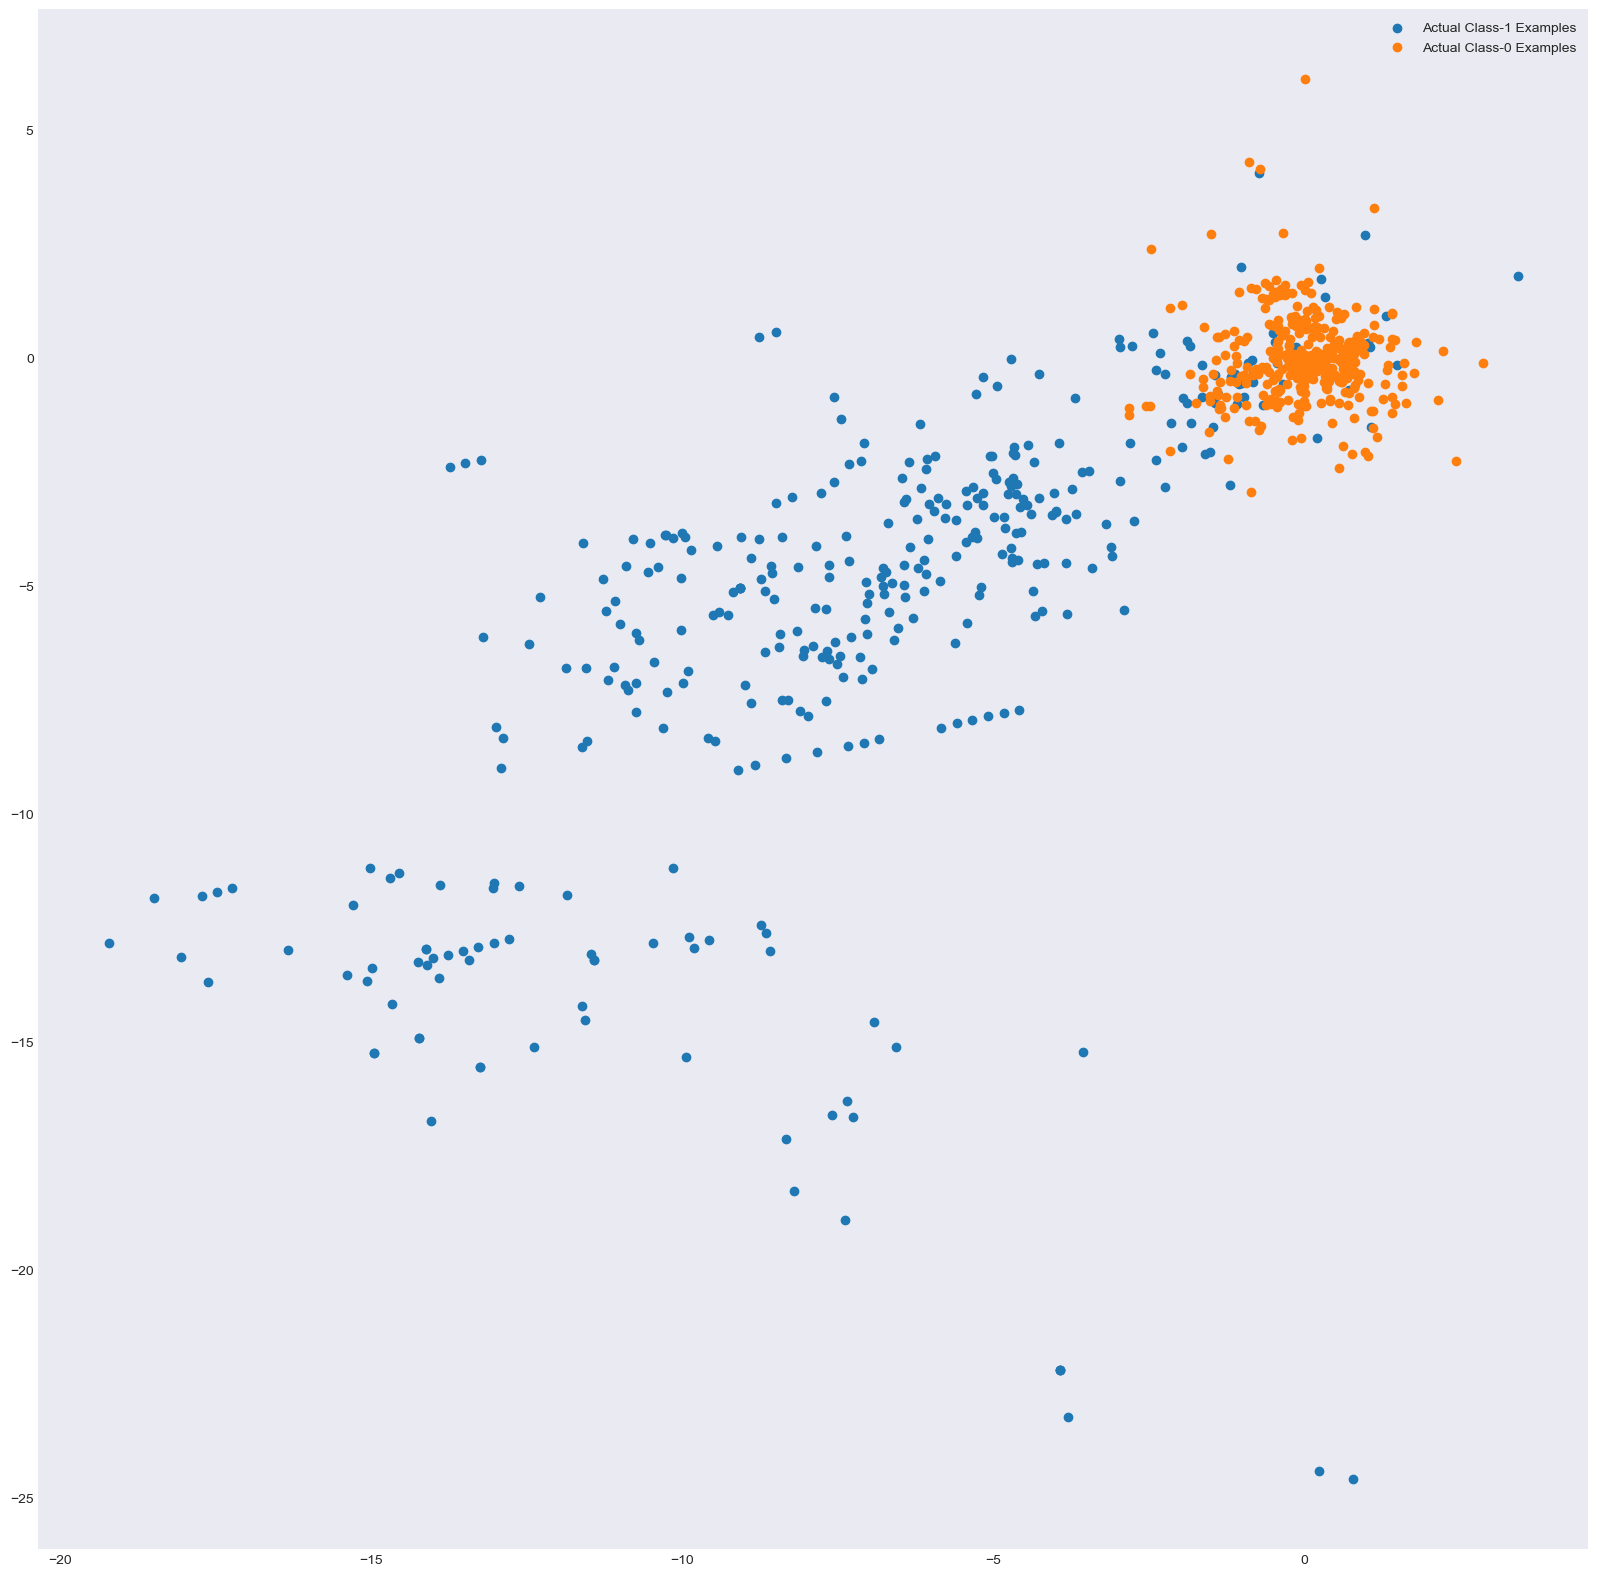

In [291]:
# Access the best Random Forest model from GridSearchCV
best_rf = clf.best_estimator_.named_steps['rf']

# Get feature importances from the best Random Forest model
var_imp = best_rf.feature_importances_

# Find the top 3 important features
top_var_index = np.argsort(var_imp)[-1]
second_top_var_index = np.argsort(var_imp)[-2]
third_top_var_index = np.argsort(var_imp)[-3]

print(f"Top variable index: {top_var_index + 1}")
print(f"2nd top variable index: {second_top_var_index + 1}")
print(f"3rd top variable index: {third_top_var_index + 1}")

# Plot the top 2 variables
X_train_1 = X_train.to_numpy()[np.where(y_train == 1.0)]
X_train_0 = X_train.to_numpy()[np.where(y_train == 0.0)]

np.random.shuffle(X_train_0)

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [20, 20]

plt.scatter(X_train_1[:, top_var_index], X_train_1[:, second_top_var_index], label='Actual Class-1 Examples')
plt.scatter(X_train_0[:X_train_1.shape[0], top_var_index], X_train_0[:X_train_1.shape[0], second_top_var_index],
            label='Actual Class-0 Examples')
plt.legend()
plt.show()

Optimal Threshold: 0.0200
False Positive Rate at optimal threshold: 0.0056
True Positive Rate at optimal threshold: 0.8943


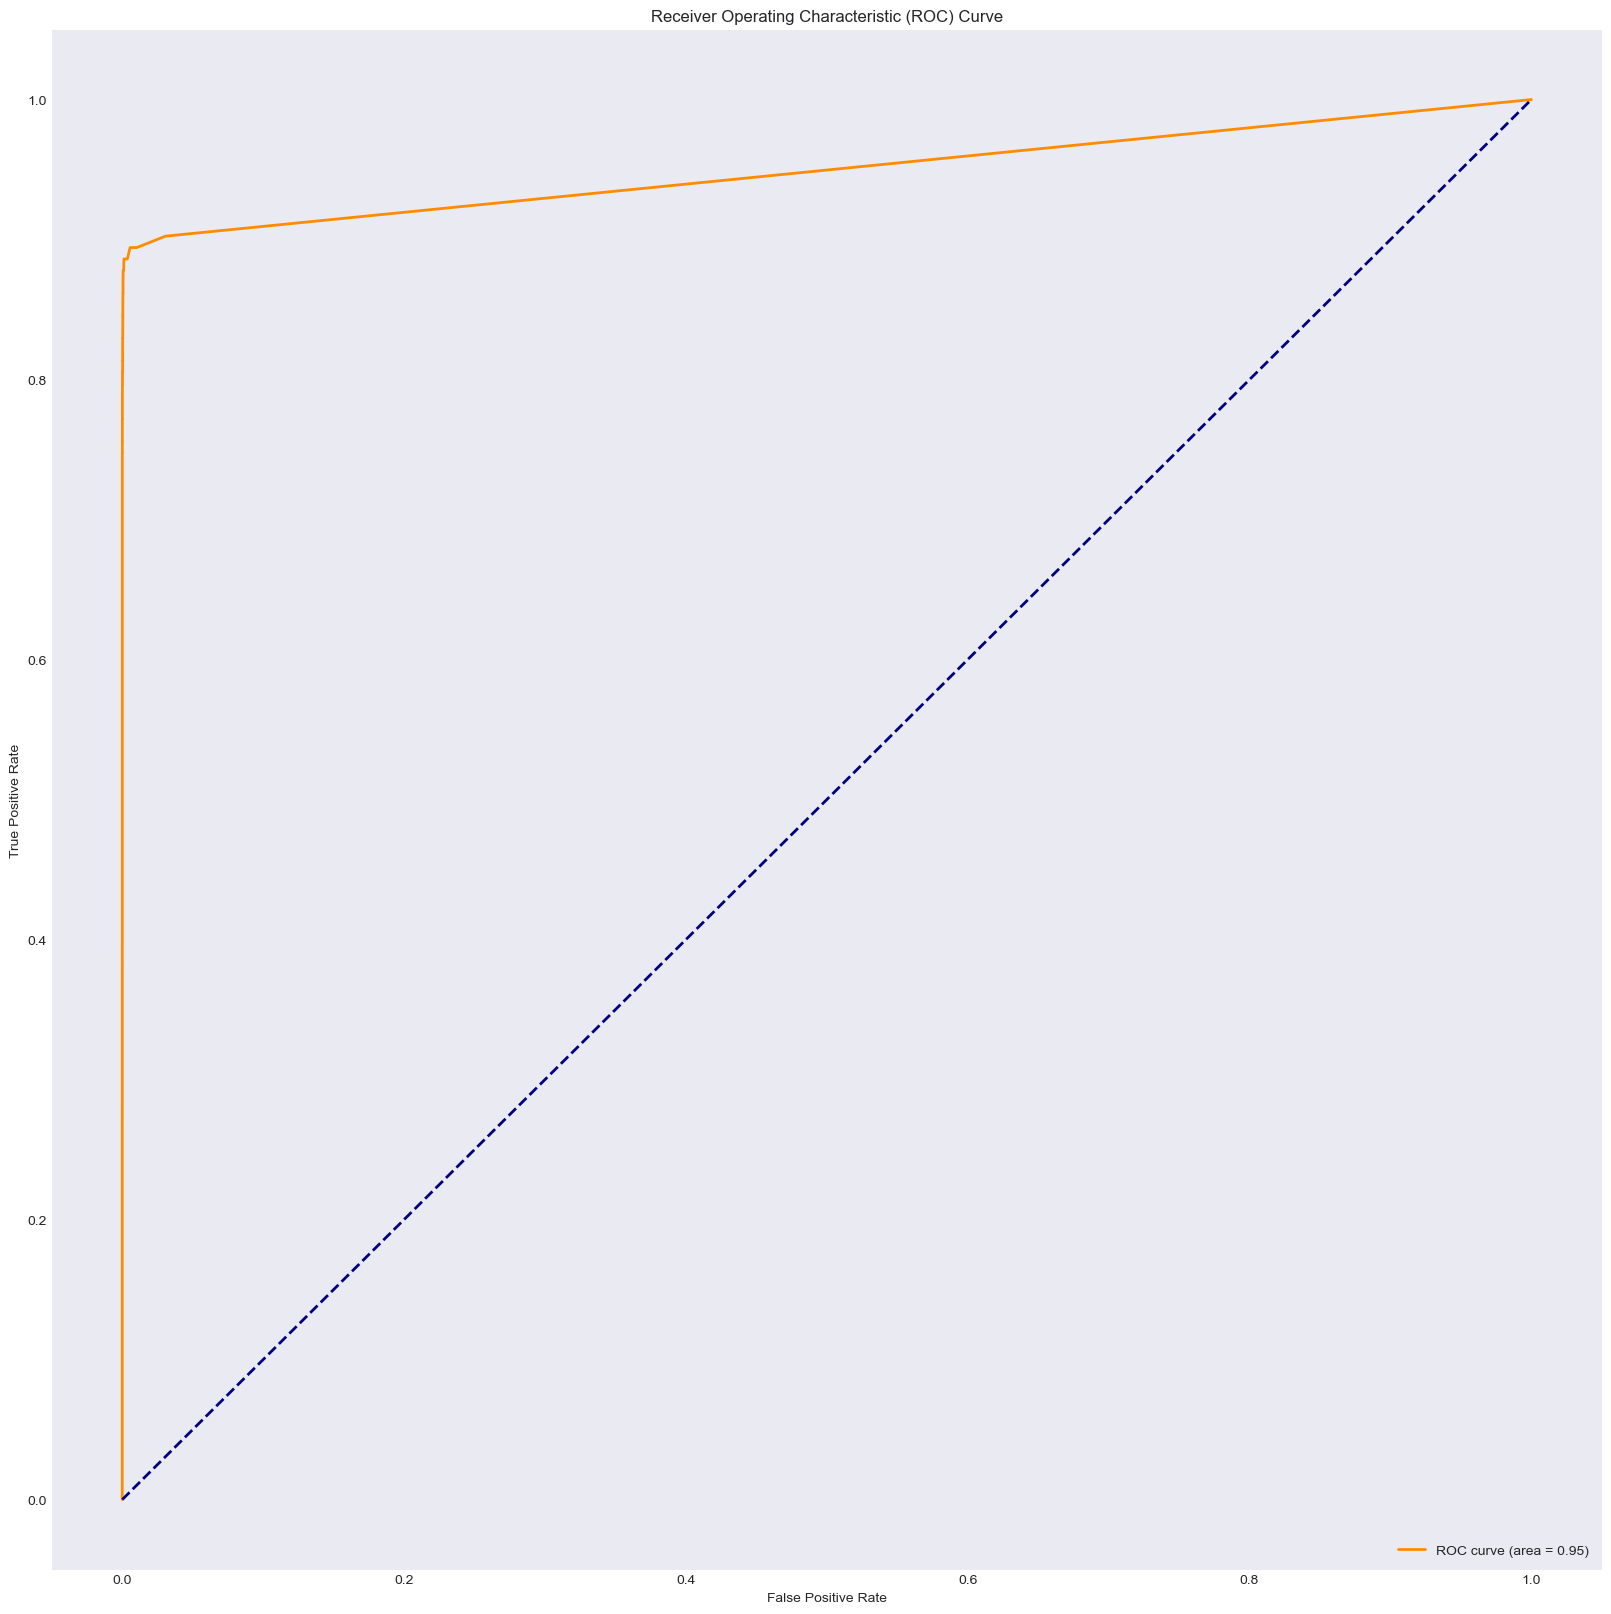

In [292]:
#### Print the FPR,TPR & select the best threshold from the roc curve
# Predict probabilities for the positive class
y_probs = clf.predict_proba(X_test)[:, 1]

# Compute the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_probs)

# Calculate the AUC (Area Under the Curve)
roc_auc = auc(fpr, tpr)

# Select the best threshold (You can define "best" in different ways. Here, we'll maximize the difference between TPR and FPR)
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

# Print the FPR, TPR, and the best threshold
print(f"Optimal Threshold: {optimal_threshold:.4f}")
print(f"False Positive Rate at optimal threshold: {fpr[optimal_idx]:.4f}")
print(f"True Positive Rate at optimal threshold: {tpr[optimal_idx]:.4f}")

# Optionally, plot the ROC curve
import matplotlib.pyplot as plt
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [293]:
from sklearn import metrics

# Calculate and print the AUC on the training data
print('Train AUC =', metrics.roc_auc_score(y_train, clf.predict_proba(X_train)[:, 1]))

# Compute the ROC curve on the test data
fpr, tpr, thresholds = metrics.roc_curve(y_test, clf.predict_proba(X_test)[:, 1])

# Select the threshold that maximizes the difference between TPR and FPR
threshold = thresholds[np.argmax(tpr - fpr)]
print('Best threshold:', threshold)

Train AUC = 1.0
Best threshold: 0.02


In [299]:
ypred = clf.predict(X_test)
print('The confusion matrix:')
confusion_matrix(y_test, ypred)

The confusion matrix:


array([[71074,     5],
       [   28,    95]])

### Comparison and Conclusion

1.``AUC Score:``
- XGBoost: 0.97 (Better)
- Random Forest with Oversampling: 0.95

**Conclusion:** XGBoost has a higher AUC score, indicating it has better performance in distinguishing between the positive and negative classes.

2.``F1-Score:``
- XGBoost: Test dataset F1-Score = 0.8520
- Random Forest with Oversampling: Test dataset F1-Score = 0.8541

**Conclusion:** The F1-scores are very close, with Random Forest having a slightly higher F1-score. This suggests that Random Forest with Oversampling may perform slightly better in terms of the F1 metric.

3.``Confusion Matrix:``
- Both models have identical confusion matrices, indicating similar performance in terms of True Positives, True Negatives, False Positives, and False Negatives. The confusion matrix shows very few false positives and false negatives, indicating good classification performance.

4.``General Observations:``
- XGBoost offers superior AUC performance, which is a more comprehensive metric as it considers all thresholds and provides a good indication of model quality.
- Random Forest with Oversampling has a slightly better F1-Score on the test dataset, suggesting it may handle the imbalance slightly better in terms of F1 performance.

### Cost analysis:

#### Operational Costs

1. Training and Deployment Time:
- XGBoost is generally faster to train and may require fewer resources due to its efficient implementation, especially with large datasets.
- Random Forest can be resource-intensive with multiple trees, especially with resampling techniques like SMOTE or ADASYN.
2. Computational Resources:
- XGBoost may have lower computational costs due to faster training times.
- Random Forest with Oversampling may incur additional costs due to the resampling process.

3. Business Costs and Benefits

1. Cost of False Positives (FP):
- False Positives: When a non-fraudulent transaction is classified as fraudulent.
- Cost Impact: Possible customer dissatisfaction or operational costs for handling false fraud alerts.
2. Cost of False Negatives (FN):
- False Negatives: When a fraudulent transaction is not identified.
- Cost Impact: Financial losses due to fraud.
3. Benefits of Improved Performance:
- XGBoost: Higher AUC score means better overall classification ability, potentially leading to fewer false negatives and better overall model performance.
- Random Forest with Oversampling: Slightly better F1-Score could imply better balance between precision and recall, reducing the risk of false negatives.

**Example Cost-Benefit Analysis:**

``Let’s assume the following costs:``

- Cost per False Positive (FP): $50
- Cost per False Negative (FN): $500
- Total Cost of Model: Includes training, deployment, and maintenance costs.

``Calculations:``

1. XGBoost:
- False Positives (FP): 5
- False Negatives (FN): 28
- Total Cost of False Positives: 5 * $50 = $250
- Total Cost of False Negatives: 28 * $500 = $14,000
- Total Cost: $250 + $14,000 = $14,250
2. Random Forest with Oversampling:
- False Positives (FP): 5
- False Negatives (FN): 28
- Total Cost of False Positives: 5 * $50 = $250
- Total Cost of False Negatives: 28 * $500 = $14,000
- Total Cost: $250 + $14,000 = $14,250

Note: If the cost of false positives and false negatives is the same for both models, the total cost remains the same. However, the benefits from improved AUC or F1-Score may not be reflected in direct monetary terms and could impact long-term operational efficiency or customer satisfaction.

``Final Recommendation:``

- XGBoost: Offers a higher AUC, indicating better performance in distinguishing between classes, which could be beneficial for overall model quality and reducing false negatives. The operational efficiency and reduced computational cost are additional benefits.
- Random Forest with Oversampling: Slightly higher F1-Score might offer better balance between precision and recall but may have higher operational costs due to resampling.

**Decision:** XGBoost is recommended if you prioritize better overall classification performance and efficiency. If balancing precision and recall is crucial and resampling fits well within your operational constraints, Random Forest with Oversampling is a good alternative.